# CartPole: rules, a neural network and more CPU cores

CartPole is a cart with a pole on top. The agent pushes the cart left (0) or right (1) and gets +1 for every step the pole stays up, so the score is the number of steps survived (500 at most in `CartPole-v1`).

The notebook has four parts:

1. **Task and Class Experiments.** The CartPole activity: state and actions, human play, hand-written rule policies and what changes when the environment is broken.
2. **NN.** A neural network that learns the policy: a Q-network with ReLU trained with DQN, made stable with double DQN and a soft target, early stopping with patience, and a CPU vs GPU time check.
3. **Cores.** Bryan's DQN lab, whose experiment is to train on several CPU cores at the same time.
4. **Comparisons.** The rule from part 1, the original DQN from part 3 and our neural network, compared on score and on time.

Every experiment prints how long it took.

---
# 1. Task and Class Experiments
---

# Class Activity: "Be the Agent" on CartPole

**Format:** pairs | **Environment:** `rl-gym` conda env | **Duration:** one class session

## Learning goals
- Identify the 4 state variables and the 2 actions.
- Understand the reward and the termination and truncation conditions.
- Build intuition for why a policy is needed before introducing DQN.

In [1]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)

## Part 1: Predict before you run 
Inspect the spaces and the outputs of `reset()` and `step()`, then fill in the table below.

In [2]:
env = gym.make("CartPole-v1")
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

obs, info = env.reset(seed=SEED)
print("reset ->", obs, info)

obs, reward, terminated, truncated, info = env.step(0)
print("step(0) ->", obs, reward, terminated, truncated, info)
obs, reward, terminated, truncated, info = env.step(1)
print("step(1) ->", obs, reward, terminated, truncated, info)

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
reset -> [ 0.01369617 -0.02302133 -0.04590265 -0.04834723] {}
step(0) -> [ 0.01323574 -0.21745604 -0.04686959  0.22950698] 1.0 False False {}
step(1) -> [ 0.00888662 -0.02169675 -0.04227945 -0.0775841 ] 1.0 False False {}


| Index | Variable | Meaning | Units | Termination limit |
|---|---|---|---|---|
| 0 | Cart position | Horizontal position of the cart on the track (0 = center) | meters (m) | ±2.4 |
| 1 | Cart velocity | How fast the cart moves along the track (negative = left, positive = right) | m/s | none |
| 2 | Pole angle | Tilt of the pole from vertical (0 = upright, positive = leaning right) | radians (rad) | ±12° (~0.21 rad) |
| 3 | Pole angular velocity | How fast the pole is tipping over (positive = falling right) | rad/s | none |

**Questions**
1. What does action 0 do? What does action 1 do?
2. What reward is given per step?
3. When does the episode end?

*Your answers:*
- Action 0 pushes the cart to the **left** and action 1 pushes it to the **right** (a fixed force of 10 N). The output confirms it: after `step(0)` the cart velocity went from -0.023 to -0.217 (accelerated left), and after `step(1)` it went back up to -0.022 (accelerated right).
- Reward is **+1 for every step** the pole stays up, including the step on which it falls. The goal is therefore to survive as long as possible. The max return is 500 in v1.
- The episode ends in two ways. **Terminated**: the pole angle exceeds ±12° (~0.21 rad) or the cart position exceeds ±2.4 (the cart leaves the track). **Truncated**: the time limit is reached, 500 steps in CartPole-v1 (200 in v0). Truncation is not a failure, it is just the clock running out.

## Part 2: Human agent
Play the game by typing actions (`0` = left, `1` = right). Use a Jupyter-friendly input prompt; press Enter on an empty line to quit.

> Requires a display. If rendering fails, remove `render_mode="human"` and rely on the printed state.

In [3]:
def play_human(seed=0, render=True):
    #env = gym.make("CartPole-v1", render_mode="human" if render else None)
    env = gym.make("CartPole-v1")

    obs, _ = env.reset(seed=seed)
    total, done = 0.0, False
    while not done:
        print(np.round(obs, 3))
        answer = input("0=left, 1=right (Enter to quit): ").strip()
        print("Action:", answer)
        if answer not in ("0", "1"):
            break
        obs, r, terminated, truncated, _ = env.step(int(answer))
        total += r
        done = terminated or truncated
    env.close()
    
    print("Score:", total)

play_human()

[ 0.014 -0.023 -0.046 -0.048]
Action: 
Score: 0.0


**Reflection**
- Which variable did you watch most? Which one did you ignore?
- Why is it hard to play with only position information?

*Your answers:*
- The most useful variables are the **pole angle** and the **pole angular velocity**, because they tell you whether the pole is falling and how fast. The one that matters least is **cart position**, since the cart has 2.4 m of room either way and only becomes relevant late in a long episode. In the printed run, the angular velocity flipped sign (-0.048, +0.23, -0.078, ...) with each alternating push, and the final pushes made it drift to -0.74 and the pole fell. The score was 8 before the episode was quit. (Edit this to reflect what you personally watched.)
- Position says nothing about the pole, which is the thing that makes the episode fail. It also gives no sense of **direction or speed**: the same position can be reached while the pole is recovering or while it is already falling. You need velocity-type information to predict where the system is going, and to react before the angle crosses the limit.

## Part 3: Design a rule-based policy
A policy is a function `policy(obs) -> action`. Evaluate each over 20 episodes.

In [4]:
def evaluate_policy(policy_fn, n_episodes=20, env_id="CartPole-v1", seed=0, **make_kwargs):
    env = gym.make(env_id, **make_kwargs)
    returns = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        total, done = 0.0, False
        while not done:
            obs, r, terminated, truncated, _ = env.step(policy_fn(obs))
            total += r
            done = terminated or truncated
        returns.append(total)
    env.close()
    return float(np.mean(returns)), float(np.std(returns))

rng = np.random.default_rng(SEED)

def random_policy(obs):
    return int(rng.integers(2))

print("Random baseline (mean, std):", evaluate_policy(random_policy))

Random baseline (mean, std): (22.9, 13.356271934937533)


In [5]:
# obs = [cart_pos, cart_vel, pole_angle, pole_ang_vel]
def policy_angle(obs):
    return 0 if obs[2] < 0 else 1

def policy_ang_vel(obs):
    return 0 if obs[3] < 0 else 1

K = 1.0  # TODO: tune
def policy_combined(obs):
    return 0 if obs[2] + K * obs[3] < 0 else 1

# TODO: write your own policy
def policy_mine(obs):
    raise NotImplementedError

policies = {
    "random": random_policy,
    "angle": policy_angle,
    "angular velocity": policy_ang_vel,
    "angle + k*ang_vel": policy_combined,
}
for name, fn in policies.items():
    mean, std = evaluate_policy(fn)
    print(f"{name:20s} mean={mean:7.1f} std={std:6.1f}")

random               mean=   24.0 std=   8.2
angle                mean=   40.9 std=   7.4
angular velocity     mean=  198.7 std=  36.3
angle + k*ang_vel    mean=  491.7 std=  36.2


| Policy | Variables used | Mean return | Std | Why it works or fails |
|---|---|---|---|---|
| random | none | 24.0 | 8.2 | Actions ignore the state, so pushes cancel out randomly and the pole falls in ~20 steps. This is the baseline. |
| angle | pole angle | 40.9 | 7.4 | Pushes toward the side the pole leans, which is the right idea. But it only reacts to where the pole *is*, not where it is *going*, so it overshoots and oscillates with growing amplitude until it falls. |
| angular velocity | pole angular velocity | 198.7 | 36.3 | Reacts to the direction of tipping, so it damps the fall. It cannot see the absolute angle, so the pole slowly drifts away from vertical (and the cart drifts off the track) over time. |
| angle + k*ang_vel | pole angle and angular velocity (K=1) | 491.7 | 36.2 | Combines position and trend of the pole, like a PD controller: the angle term corrects the lean and the velocity term anticipates and damps overshoot. Near the 500 cap. |
| my policy | not implemented (`policy_mine` still raises `NotImplementedError`) | – | – | Write it, add it to the `policies` dict, and fill this row. Ideas: tune K, or add cart position and velocity terms to keep the cart centered. |

Note: the random row varies between runs because `rng` is shared and stateful (the first call printed 22.9 ± 13.4, the second 24.0 ± 8.2).

## Part 4: Break the environment
Pick **one** experiment and report back to the class.

The cell only prints one initial state. To measure the effect, pass the same options to env.reset() inside evaluate_policy() and compare returns for the default and wide ranges

In [6]:
# Experiment A: larger initial-state noise (default is +/-0.05)
env = gym.make("CartPole-v1")
obs, _ = env.reset(seed=SEED, options={"low": -0.3, "high": 0.3})
print("Initial state with larger noise:", obs)
env.close()

Initial state with larger noise: [ 0.08217701 -0.13812797 -0.2754159  -0.2900834 ]


In [7]:
# Experiment B: change termination thresholds
env = gym.make("CartPole-v1")
env.unwrapped.theta_threshold_radians = 0.4  # default ~0.2095
env.unwrapped.x_threshold = 4.8              # default 2.4
obs, _ = env.reset(seed=SEED)
done, steps = False, 0
while not done:
    obs, r, terminated, truncated, _ = env.step(policy_combined(obs))
    steps += 1
    done = terminated or truncated
print("Steps survived:", steps, "| terminated:", terminated, "| truncated:", truncated)
env.close()

Steps survived: 500 | terminated: False | truncated: True


In [8]:
# Experiment C: remove one variable from the policy and observe the degradation
def policy_no_vel(obs):
    return 0 if obs[2] < 0 else 1

print("full policy   :", evaluate_policy(policy_combined))
print("without ang_vel:", evaluate_policy(policy_no_vel))

full policy   : (491.7, 36.178861231387586)
without ang_vel: (40.9, 7.38173421358423)


In [9]:
# Experiment D: CartPole-v0 (200 steps) vs v1 (500 steps): truncation vs termination
for env_id in ("CartPole-v0", "CartPole-v1"):
    print(env_id, evaluate_policy(policy_combined, env_id=env_id))

CartPole-v0 (200.0, 0.0)
CartPole-v1 (491.7, 36.178861231387586)


c:\Dev\ai\ai-playground\.venv\Lib\site-packages\gymnasium\envs\registration.py:513: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


*Experiment chosen and findings:*

- **Experiment C (remove a variable) and D (v0 vs v1)**, using the printed results:
  - **C:** the full policy (angle + ang_vel) scored **491.7**, while removing angular velocity dropped it to **40.9**. A single missing variable cut performance by more than 10x, so the velocity information is essential.
  - **D:** CartPole-v0 gave **200.0 ± 0.0**, v1 gave **491.7 ± 36.2**. The same policy is never terminated in v0; it simply hits the 200-step time limit every time (zero std). This is **truncation, not failure**, so the score reflects the time limit rather than skill.
  - **B** (for reference): with the thresholds widened (angle 0.4 rad, x 4.8) the policy survived all 500 steps and was truncated, so looser termination limits make the task easier.
  - **A** only prints one noisy initial state (angle -0.275, already past the 0.21 limit's neighborhood). To measure its effect, pass `options={"low": -0.3, "high": 0.3}` to `env.reset()` inside `evaluate_policy`.

## Part 5: Debrief and bridge to DQN
Discuss:
- Which variables were most informative? Why does angular velocity matter more than position?
- Why can't we use a table (Q-learning) directly? (The state is continuous.)
- What would a neural network need as input and output? (4 inputs, 2 Q-values.)

*Discussion notes:*
- Pole angle and angular velocity are the most informative. Angular velocity matters more than position because it is a *predictor*: it tells you where the pole will be in the next few steps, so you can correct before the angle limit is crossed. Position only tells you where it is now. That is why "angular velocity" alone (198.7) beat "angle" alone (40.9).
- All four variables are continuous (real numbers), so there are infinitely many states, and a Q-table needs a finite number of rows. Discretizing into 10 bins per variable already gives 10,000 states x 2 actions = 20,000 Q-values, and this grows exponentially (N^4) with finer bins. Also, neighboring states in a table do not share what they learn.
- A neural network takes the 4 state variables as input and outputs 2 Q-values, one per action (left, right). It generalizes across nearby states, and the policy is "pick the action with the larger Q-value".

## Deliverable
A short worksheet containing the filled variable table, the policy comparison table, and a 3-sentence explanation of why the best policy worked.

*Explanation (3 sentences):*

- The best policy (`angle + k*ang_vel`) works because it looks at both where the pole is leaning and how fast it is moving. Pushing in the direction of the lean corrects the angle, while the velocity term anticipates the motion and damps overshoot, so the pole is held near vertical. Policies using only one of these signals either overshoot (angle only) or drift (angular velocity only), so they fail much earlier.

## Optional extensions

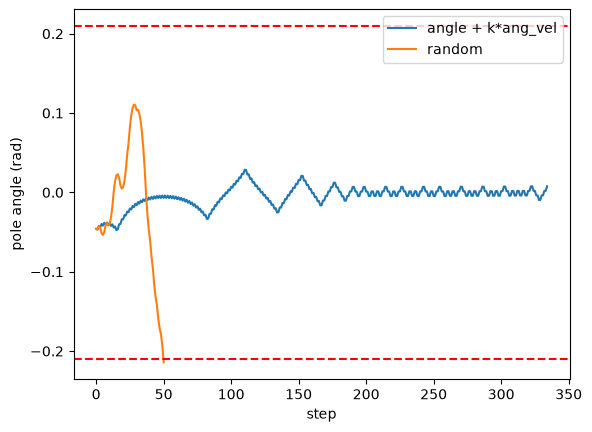

In [10]:
# Plot pole angle vs time for a good and a bad policy
def angle_trace(policy_fn, seed=0):
    env = gym.make("CartPole-v1")
    obs, _ = env.reset(seed=seed)
    angles, done = [obs[2]], False
    while not done:
        obs, _, terminated, truncated, _ = env.step(policy_fn(obs))
        angles.append(obs[2])
        done = terminated or truncated
    env.close()
    return angles

plt.plot(angle_trace(policy_combined), label="angle + k*ang_vel")
plt.plot(angle_trace(random_policy), label="random")
plt.axhline(0.2095, color="r", ls="--")
plt.axhline(-0.2095, color="r", ls="--")
plt.xlabel("step")
plt.ylabel("pole angle (rad)")
plt.legend()
plt.show()

In [11]:
# Q-table size if each variable is discretized into N bins
n_bins = 10  # TODO: try other values
n_states = n_bins ** 4
n_actions = 2
print(f"{n_bins} bins/variable -> {n_states:,} states x {n_actions} actions = {n_states * n_actions:,} Q-values")

10 bins/variable -> 10,000 states x 2 actions = 20,000 Q-values


---
# 2. NN: a neural network that balances the pole
---
In part 1 the policy was a rule we wrote by hand. Here the policy is learned. A neural network reads the 4 state variables and returns one value per action (the Q-value), and the agent pushes in the direction with the larger value. This is DQN.

**What part 1 tells us about the design**
- Angle and angular velocity were both needed (Experiment C), so the network gets all 4 variables and returns 2 Q-values.
- The score is the episode return (steps survived), not the loss. A time-limit cut (truncation) is not a failure, so only `terminated` is stored as a terminal state.
- Returns are capped at 500 and noisy, so the final score is the mean over 50 new episodes that were never used to tune anything.

**The agent**
- Network 4 → 128 → 128 → 2, ReLU after both hidden layers, linear output (17,410 parameters).
- ε-greedy exploration (ε from 1.0 to 0.05 over 5,000 steps), replay buffer of 20,000 transitions, batches of 64, Huber loss, Adam (lr 5e-4), γ = 0.99.
- **Double DQN:** the online network chooses the next action and the target network scores it.
- **Soft target:** after every update the target moves a small step (τ = 0.02) towards the online network, instead of a full copy every 300 steps.
- **Patience:** every 1,000 steps the greedy policy plays 10 validation episodes. We keep the best weights and stop after P checks in a row without improvement. A grace period (no stopping before step 15,000) keeps an early plateau from ending the run.

In [11]:
import os, copy, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import gymnasium as gym
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

NN_DEFAULT_THREADS = torch.get_num_threads()    # what torch would use on its own
torch.set_num_threads(1)                        # a 128-unit MLP gains nothing from threads (measured below)

class NNQNetwork(nn.Module):
    """Q(s, .): 4 state variables in -> 2 Q-values out, ReLU between the layers, linear output."""
    def __init__(self, n_hidden=128, dropout=0.0):
        super().__init__()
        layers = [nn.Linear(4, n_hidden), nn.ReLU()]
        if dropout: layers.append(nn.Dropout(dropout))
        layers += [nn.Linear(n_hidden, n_hidden), nn.ReLU()]
        if dropout: layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(n_hidden, 2))                  # no activation: a Q-value can be any real number
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class NNReplayBuffer:
    """Ring buffer of the last `capacity` transitions (s, a, r, s', terminated)."""
    def __init__(self, capacity):
        self.s  = np.zeros((capacity, 4), np.float32); self.s2 = np.zeros((capacity, 4), np.float32)
        self.a  = np.zeros(capacity, np.int64); self.r = np.zeros(capacity, np.float32); self.d = np.zeros(capacity, np.float32)
        self.cap, self.n, self.i = capacity, 0, 0

    def add(self, s, a, r, s2, d):
        self.s[self.i], self.a[self.i], self.r[self.i], self.s2[self.i], self.d[self.i] = s, a, r, s2, d
        self.i = (self.i + 1) % self.cap
        self.n = min(self.n + 1, self.cap)

    def sample(self, k, rng):
        idx = rng.integers(0, self.n, k)
        return self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.d[idx]


def nn_run_policy(q, seeds):
    """Mean return of the greedy policy argmax_a Q(s, a) on the given start seeds (eval mode: no dropout)."""
    q = copy.deepcopy(q).cpu().eval()
    env, rets = gym.make("CartPole-v1"), []
    for sd in seeds:
        o, _ = env.reset(seed=int(sd)); tot, done = 0.0, False
        while not done:
            with torch.no_grad():
                a = int(q(torch.as_tensor(o, dtype=torch.float32)).argmax())
            o, r, te, tr, _ = env.step(a); tot += r; done = te or tr
        rets.append(tot)
    env.close()
    return float(np.mean(rets))


class PatienceStopper:
    """Call update(score, step) once per validation. A score is an improvement only if it beats the best so far
    by more than min_delta. After `patience` validations in a row without improvement it says stop.
    GRACE PERIOD: validations before step `start_from` can still improve the best score (and are checkpointed)
    but never count as "no improvement", so early plateaus cannot stop training. patience=None never stops."""
    def __init__(self, patience, min_delta=1.0, start_from=0):
        self.patience, self.min_delta, self.start_from = patience, min_delta, start_from
        self.best, self.bad = -float("inf"), 0

    def update(self, score, step=None):
        improved = score > self.best + self.min_delta
        if improved:
            self.best, self.bad = score, 0
        elif step is None or step >= self.start_from:
            self.bad += 1
        return improved, (self.patience is not None and self.bad >= self.patience)


def nn_sync(device):
    """CUDA is asynchronous: wait for the GPU before reading the clock."""
    if device.type == "cuda":
        torch.cuda.synchronize()


def train_nn(seed=0, steps=30_000, device="cpu", hidden=128, gamma=0.99, lr=5e-4, batch=64, buffer=20_000,
             target_sync=300, tau=None, double=False, dropout=0.0,
             eps_end=0.05, eps_decay=5_000, learn_start=1_000, clip=10.0,
             patience=None, grace=0, eval_every=1_000, val_episodes=10, min_delta=1.0,   # PATIENCE: optional, off by default
             diagnostics=False):
    torch.set_num_threads(1)
    device = torch.device(device)
    rng = np.random.default_rng(seed); torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    q, q_t = NNQNetwork(hidden, dropout).to(device), NNQNetwork(hidden, dropout).to(device)
    q_t.load_state_dict(q.state_dict()); q_t.eval()
    opt, buf = torch.optim.Adam(q.parameters(), lr=lr), NNReplayBuffer(buffer)
    val_seeds = range(10_000, 10_000 + val_episodes)               # validation episodes (never used as test)

    stopper = PatienceStopper(patience, min_delta, grace)          # PATIENCE (+ grace period)
    best_state, best_step, stopped_step, evals, diag = None, 0, None, [], []   # PATIENCE: (step, validation score)
    t_eval, loss_acc, loss_n = 0.0, 0.0, 0
    o, _ = env.reset(seed=1_000 + seed)                             # training starts differ from validation/test seeds
    nn_sync(device); t0 = time.perf_counter()
    for step in range(1, steps + 1):
        eps = max(eps_end, 1.0 - (1.0 - eps_end) * step / eps_decay)
        if rng.random() < eps:                                      # explore
            a = int(rng.integers(2))
        else:                                                       # exploit: argmax_a Q(s, a)
            q.eval()
            with torch.no_grad():
                a = int(q(torch.as_tensor(o, dtype=torch.float32, device=device)).argmax())
            q.train()
        o2, r, te, tr, _ = env.step(a)
        buf.add(o, a, r, o2, float(te))                             # store `terminated` only, not `truncated`
        o = o2
        if te or tr:
            o, _ = env.reset()

        if buf.n >= learn_start:
            s, a_, r_, s2, d = (torch.as_tensor(x, device=device) for x in buf.sample(batch, rng))
            q_sa = q(s).gather(1, a_.unsqueeze(1)).squeeze(1)
            with torch.no_grad():
                if double:                                          # DOUBLE DQN: online net picks, target net scores
                    nxt = q_t(s2).gather(1, q(s2).argmax(1, keepdim=True)).squeeze(1)
                else:                                               # plain DQN: target net picks and scores
                    nxt = q_t(s2).max(1).values
                y = r_ + gamma * (1 - d) * nxt
            loss = F.smooth_l1_loss(q_sa, y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(q.parameters(), clip)
            opt.step()
            loss_acc += float(loss) if diagnostics else 0.0; loss_n += 1
            if tau is not None:                                     # SOFT target: blend a little every step
                with torch.no_grad():
                    for p, pt in zip(q.parameters(), q_t.parameters()):
                        pt.mul_(1 - tau).add_(p, alpha=tau)
            elif step % target_sync == 0:                           # HARD target: copy every `target_sync` steps
                q_t.load_state_dict(q.state_dict())

        # ---- PATIENCE: every `eval_every` steps score the greedy policy and decide -------------------
        if step % eval_every == 0:
            nn_sync(device); te0 = time.perf_counter()
            score = nn_run_policy(q, val_seeds)                     # validation return
            t_eval += time.perf_counter() - te0
            evals.append((step, score))
            if diagnostics:
                m = min(buf.n, 2000); idx = (buf.i - 1 - np.arange(m)) % buf.cap
                with torch.no_grad():
                    q.eval(); mq = float(q(torch.as_tensor(buf.s[idx], device=device)).max(1).values.mean()); q.train()
                diag.append(dict(step=step, val=score, loss=loss_acc / max(loss_n, 1), mean_maxq=mq,
                                 term_frac=float(buf.d[:buf.n].mean())))
                loss_acc, loss_n = 0.0, 0
            improved, stop = stopper.update(score, step)
            if improved:                                            # new best -> keep a checkpoint
                best_step, best_state = step, copy.deepcopy(q.state_dict())
            if stop:                                                # patience exhausted -> early stop
                stopped_step = step
                break
    nn_sync(device); seconds = time.perf_counter() - t0
    env.close()

    q_last = copy.deepcopy(q).cpu().eval()                          # weights at the last step
    if best_state is not None:                                      # PATIENCE: return the BEST weights seen
        q.load_state_dict(best_state)
    q = q.cpu().eval()
    return dict(q=q, q_last=q_last, evals=evals, diag=diag, best_val=stopper.best, best_step=best_step,
                stopped_step=stopped_step, steps_used=step, seconds=seconds, eval_seconds=t_eval,
                train_seconds=seconds - t_eval)

print("torch", torch.__version__, "| gymnasium", gym.__version__, "| logical cores:", os.cpu_count(),
      "| torch default threads:", NN_DEFAULT_THREADS)

torch 2.11.0+cu128 | gymnasium 1.3.0 | logical cores: 8 | torch default threads: 4


In [12]:
# The ReLU network, then a short training run (time is printed)
q0 = NNQNetwork()
print(q0)
print(f"{sum(p.numel() for p in q0.parameters()):,} parameters (the 10-bin Q-table above had {n_states * n_actions:,} entries, only for discretised states)")
_o, _ = gym.make("CartPole-v1").reset(seed=SEED)
print("obs  ->", _o); print("Q(s) ->", q0(torch.as_tensor(_o)).detach().numpy(), "(untrained: Q(s, left), Q(s, right))")

t0 = time.perf_counter()
smoke = train_nn(seed=SEED, steps=3_000, double=True, tau=0.02, eval_every=1_000)
print(f"\n3,000 steps in {smoke['seconds']:.1f} s ({smoke['eval_seconds']:.1f} s of it validation)")
print("validation return every 1,000 steps:", [round(s) for _, s in smoke["evals"]])
print("same evaluation as in part 1 (20 episodes, seeds 0-19):", evaluate_policy(lambda ob: int(smoke["q"](torch.as_tensor(ob, dtype=torch.float32)).argmax())))

NNQNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
17,410 parameters (the 10-bin Q-table above had 20,000 entries, only for discretised states)
obs  -> [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
Q(s) -> [ 0.03346011 -0.00573776] (untrained: Q(s, left), Q(s, right))



3,000 steps in 6.9 s (1.0 s of it validation)
validation return every 1,000 steps: [75, 288, 215]


same evaluation as in part 1 (20 episodes, seeds 0-19): (283.9, 20.82282401596863)


In [13]:
# Checks: ReLU layers, the patience rule, grace period, double DQN, and that the best weights are returned
assert sum(isinstance(m, nn.ReLU) for m in NNQNetwork().modules()) == 2, "ReLU after both hidden layers"
assert isinstance(list(NNQNetwork().net)[-1], nn.Linear), "linear output layer"

st = PatienceStopper(patience=3, min_delta=1.0)
for score, expected in [(10, (True, False)), (20, (True, False)), (20, (False, False)),
                        (20.5, (False, False)), (19, (False, True))]:      # 3rd bad validation -> stop
    assert st.update(score) == expected, (score, expected)
assert st.best == 20 and st.bad == 3 and PatienceStopper(None).update(0.0)[1] is False
g = PatienceStopper(patience=2, min_delta=1.0, start_from=3000)             # grace period: nothing counts as "bad" before step 3000
assert [g.update(s, st_) for s, st_ in [(10, 1000), (5, 2000), (5, 2500)]] == [(True, False), (False, False), (False, False)] and g.bad == 0
assert g.update(5, 3000) == (False, False) and g.update(5, 4000) == (False, True), "counting starts at start_from"
assert PatienceStopper(patience=2, start_from=3000).update(50, 1000) == (True, False), "improvements inside the grace period still count"

KW = dict(steps=4_000, learn_start=500, eval_every=500, double=True, tau=0.02)
t0 = time.perf_counter()
full, pat = train_nn(**KW), train_nn(**KW, patience=1)
gr = train_nn(**KW, patience=1, grace=2_000)
assert gr["steps_used"] >= 2_000 and gr["evals"] == full["evals"][:len(gr["evals"])], "grace period delays the stop"
assert pat["stopped_step"] is not None and pat["steps_used"] < 4_000, "patience=1 should stop early"
assert pat["evals"] == full["evals"][:len(pat["evals"])], "a patience run must follow the full run until it stops"
assert nn_run_policy(pat["q"], range(10_000, 10_010)) == pat["best_val"], "the returned weights are the best checkpoint"
plain = train_nn(steps=1_500, learn_start=500, eval_every=500)
dbl   = train_nn(steps=1_500, learn_start=500, eval_every=500, double=True)
assert not all(torch.equal(a, b) for a, b in zip(plain["q"].state_dict().values(), dbl["q"].state_dict().values())), "double DQN must change the update"
print(f"NN: all checks passed in {time.perf_counter()-t0:.0f} s (patience=1 stopped at step {pat['stopped_step']}, best checkpoint at step {pat['best_step']})")

NN: all checks passed in 29 s (patience=1 stopped at step 1000, best checkpoint at step 500)


## Why does plain DQN collapse?
Plain DQN (hard target copy every 300 steps, no double DQN) often reaches 500 on the validation episodes and then falls back to 100–300. Before changing anything we look at the loss, the mean of the largest Q-value over recent states, and the share of failure transitions in the replay buffer.

3 plain-DQN runs of 12,000 steps in parallel: 49 s wall | per run: [42, 41, 42] s

seed 0:  step   val   loss  mean maxQ  failure transitions in buffer
            2000   276  0.046       3.9         3.25%
            4000   443  0.126      10.5         2.13%
            6000   182  0.148      15.8         1.50%
            8000   131  0.166      21.0         1.26%
           10000   155  0.186      25.8         1.15%
           12000   139  0.202      30.4         1.08%
seed 1:  step   val   loss  mean maxQ  failure transitions in buffer
            2000    95  0.052       4.0         4.50%
            4000   170  0.120      10.9         2.82%
            6000   209  0.160      15.7         2.03%
            8000   184  0.185      21.2         1.65%
           10000   478  0.206      26.4         1.43%
           12000   132  0.200      34.2         1.27%
seed 2:  step   val   loss  mean maxQ  failure transitions in buffer
            2000   489  0.049       3.9         4.30%
        

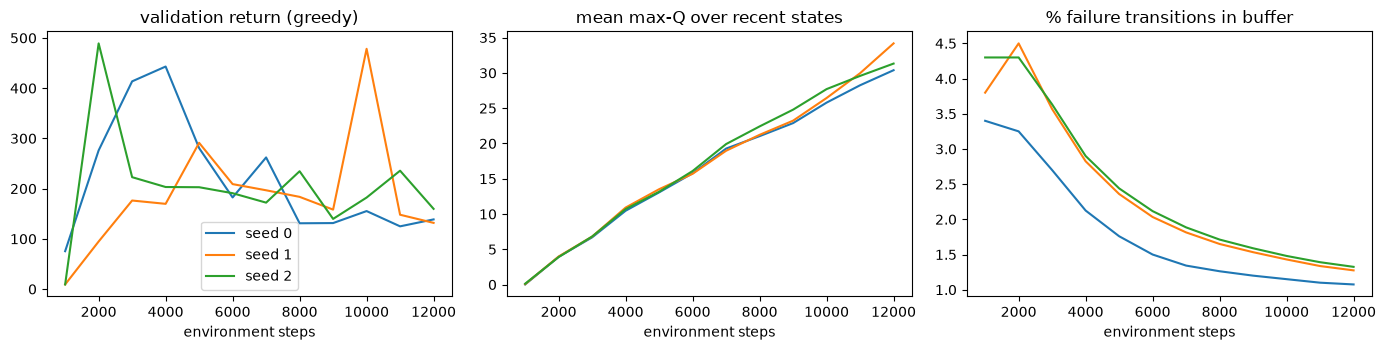

In [14]:
def nn_diag_job(seed):
    out = train_nn(seed=seed, steps=12_000, diagnostics=True)
    return dict(seed=seed, diag=out["diag"], seconds=out["seconds"])

t0 = time.perf_counter()
diag_runs = Parallel(n_jobs=3)(delayed(nn_diag_job)(s) for s in (0, 1, 2))
print(f"3 plain-DQN runs of 12,000 steps in parallel: {time.perf_counter()-t0:.0f} s wall | per run: {[round(r['seconds']) for r in diag_runs]} s\n")
for r in diag_runs:
    print(f"seed {r['seed']}:  step   val   loss  mean maxQ  failure transitions in buffer")
    for d in r["diag"][1::2]:
        print(f"          {d['step']:6d} {d['val']:5.0f} {d['loss']:6.3f} {d['mean_maxq']:9.1f} {100*d['term_frac']:12.2f}%")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for r in diag_runs:
    st = [d["step"] for d in r["diag"]]
    ax[0].plot(st, [d["val"] for d in r["diag"]], label=f"seed {r['seed']}")
    ax[1].plot(st, [d["mean_maxq"] for d in r["diag"]])
    ax[2].plot(st, [100 * d["term_frac"] for d in r["diag"]])
ax[0].set_title("validation return (greedy)"); ax[1].set_title("mean max-Q over recent states"); ax[2].set_title("% failure transitions in buffer")
for a_ in ax: a_.set_xlabel("environment steps")
ax[0].legend(); plt.tight_layout(); plt.show()

Plain DQN, 3 seeds, 12,000 steps each.

- **The greedy policy is unstable.** Validation return on seed 0 went 276 → 443 → 182 → 131 → 155 → 139. On seed 1 it was 478 at step 10,000 and 132 at step 12,000, and on seed 2 it was 489 at step 2,000 and 160 at step 12,000. Weights from an arbitrary step can be much worse than weights from a few thousand steps earlier, which is why we keep the best checkpoint.
- **The value scale keeps growing.** The mean max-Q rises from about 4 at step 2,000 to 30–34 at step 12,000 with no sign of levelling off, and the loss also keeps rising (0.05 → 0.20–0.24). The action choice depends on a small difference between two large numbers. This is a working explanation that fits the swings; we did not test it with an intervention.
- **Failure transitions get rare in the buffer:** 3.3–4.5% at step 2,000 against 1.1–1.3% at step 12,000, so the network sees less and less evidence of what failing looks like.

## Which change helps? (earlier tuning runs)
These runs were done outside the notebook because they are about 40 trainings of 30,000 steps. They used other training seeds (100–102 and 200–204) and other test episodes (seeds 20,000–20,049) than the final experiment. The score is the mean over 50 test episodes, for the best checkpoint and for the last weights.

| Change (5 seeds, 200–204) | Best checkpoint | Last weights |
|---|---|---|
| plain DQN | 413.3 | 300.9 |
| double DQN + soft target, τ = 0.005 | 498.3 | 454.8 |
| double DQN + soft target, τ = 0.01 | 495.5 | 401.3 |
| **double DQN + soft target, τ = 0.02** | **500.0** | **500.0** |
| double DQN + soft target, τ = 0.05 | 231.0 | 60.8 |

On 3 other seeds (100–102), where plain DQN scored 474.3 / 262.1, these did not help: double DQN alone (402.0 / 413.1), soft target alone (410.6 / 382.4), a lower discount γ = 0.95 or 0.98 (375.4 / 130.1 and 323.0 / 216.3), a bigger buffer of 100,000 (403.3 / 170.0), a higher learning rate (391.9 / 270.6). Scaling the inputs fixed the best checkpoint (498.2) but not the last weights (212.9).

- A lower γ fits what we saw in part 1: the cart drifts off the track hundreds of steps after the mistake, so the agent needs a long horizon.
- Neither change was enough alone. Double DQN and the soft target worked together.
- τ = 0.02 sits next to a cliff (τ = 0.05 collapses), and it was chosen because it won among about a dozen settings on few seeds, so part of that win is luck. The next experiment tests it on seeds nobody tuned on.

## A first attempt on new seeds (300–304) and what went wrong
We first tested the recipe on new training seeds 300–304 (test seeds 30,000–30,049, 30,000 steps). It did not win:

| Run | Test return (mean) | Steps used |
|---|---|---|
| plain DQN, last weights | 472.0 | 30,000 |
| plain DQN, best checkpoint restored | 500.0 | 30,000 |
| improved DQN, last weights | 401.8 | 30,000 |
| improved DQN + patience P = 3 | 256.9 | 7,400 |
| improved DQN + patience P = 5 | 264.6 | 10,200 |
| improved DQN + patience P = 10 | 498.9 | 23,600 |

- With its best checkpoint, plain DQN already scored 500 on every one of these seeds, so there was little for the recipe to improve.
- P = 3 and P = 5 stopped during the plateau before the score jumps to 500 (between steps 11,000 and 19,000 in these runs), so they returned weak checkpoints. P = 10 waited long enough. That is why the next experiment adds a grace period.
- One improved run scored 500 four times and ended with a dead network (score 9). The last weights are not safe, the best checkpoint is.
- One run with dropout 0.1 scored 343.8 on the last weights, below 401.8 without it. One run is weak evidence, but we did not follow dropout further.

---
## Experiment: plain DQN vs improved DQN vs improved DQN with patience
---
New training seeds 400–404 and new test episodes (seeds 40,000–40,049) that were not used for any tuning. 30,000 steps per run.

- **Plain DQN:** hard target copy every 300 steps, no double DQN.
- **Improved DQN:** double DQN + soft target (τ = 0.02).
- **Improved DQN + patience (patience ON):** the same, with early stopping. No stop before step 15,000, then stop after 10 checks without improvement, and return the best weights.

For the first two we report the last weights and the best checkpoint of the same run, so restoring the best weights can be separated from the recipe.

In [15]:
NN_FINAL_SEEDS = (400, 401, 402, 403, 404)
NN_TEST_SEEDS  = range(40_000, 40_050)
NN_GRACE, NN_PATIENCE = 15_000, 10

NN_FINAL_RUNS = {                                    # label -> kwargs of train_nn
    "N0 plain DQN":                       dict(),                                              # patience OFF
    "N1 recipe (double + soft target)":   dict(double=True, tau=0.02),                          # patience OFF
    "N2 recipe + grace patience":         dict(double=True, tau=0.02, patience=NN_PATIENCE, grace=NN_GRACE),   # <- patience ON
}

def nn_final_job(label, cfg, seed):
    out = train_nn(seed=seed, steps=30_000, **cfg)
    return dict(label=label, seed=seed, best=nn_run_policy(out["q"], NN_TEST_SEEDS), last=nn_run_policy(out["q_last"], NN_TEST_SEEDS),
                steps_used=out["steps_used"], best_step=out["best_step"], stopped_step=out["stopped_step"],
                seconds=out["seconds"], eval_seconds=out["eval_seconds"], evals=out["evals"], best_val=out["best_val"])

t0 = time.perf_counter()
nn_jobs = [(lb, c, s) for lb, c in NN_FINAL_RUNS.items() for s in NN_FINAL_SEEDS]
nn_final = Parallel(n_jobs=8)(delayed(nn_final_job)(*j) for j in nn_jobs)
NN_FINAL_WALL = time.perf_counter() - t0
print(f"{len(nn_jobs)} trainings, 8 in parallel: {NN_FINAL_WALL:.0f} s wall ({NN_FINAL_WALL/60:.1f} min); sum of run times {sum(r['seconds'] for r in nn_final):.0f} s\n")

print(f"{'run':36s} {'weights':>9s} {'test by seed (400-404)':>28s} {'mean ± std':>14s} {'steps used':>11s} {'s / run':>8s}")
nn_table = {}
for lb in NN_FINAL_RUNS:
    rs = [r for r in nn_final if r["label"] == lb]
    for key, nm in ((("last", "last"), ("best", "best ckpt")) if "grace" not in lb else (("best", "best ckpt"),)):
        t = np.array([r[key] for r in rs]); used = np.mean([r["steps_used"] for r in rs]); secs = np.mean([r["seconds"] for r in rs])
        nn_table[(lb, key)] = (t, used, secs)
        print(f"{lb:36s} {nm:>9s} {str([round(x) for x in t]):>28s} {t.mean():7.1f} ±{t.std():5.1f} {used:11.0f} {secs:8.0f}")
print("\nRule angle + 1.0*ang_vel from part 1: 491.7 ± 36.2 (seeds 0-19)")

15 trainings, 8 in parallel: 297 s wall (4.9 min); sum of run times 1984 s

run                                    weights       test by seed (400-404)     mean ± std  steps used  s / run
N0 plain DQN                              last     [191, 154, 180, 70, 147]   148.4 ± 42.4       30000      141
N0 plain DQN                         best ckpt    [283, 500, 500, 254, 296]   366.7 ±109.7       30000      141
N1 recipe (double + soft target)          last        [9, 9, 500, 500, 500]   303.7 ±240.4       30000      151
N1 recipe (double + soft target)     best ckpt    [500, 408, 500, 500, 493]   480.3 ± 36.0       30000      151
N2 recipe + grace patience           best ckpt    [500, 408, 500, 500, 493]   480.3 ± 36.0       24200      105

Rule angle + 1.0*ang_vel from part 1: 491.7 ± 36.2 (seeds 0-19)


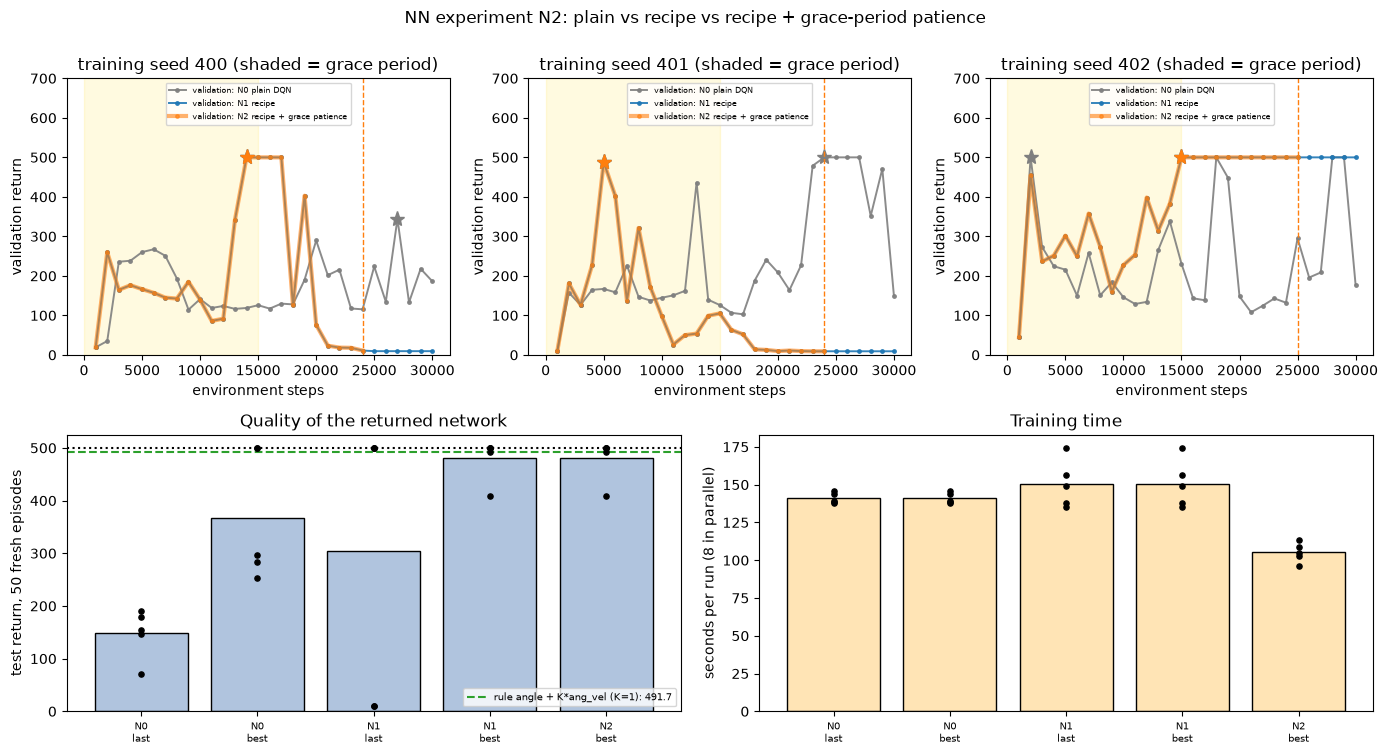

In [16]:
fig = plt.figure(figsize=(14, 7.5)); gs = fig.add_gridspec(2, 6)
for c_, sd in enumerate((400, 401, 402)):
    ax = fig.add_subplot(gs[0, 2*c_:2*c_+2])
    for lb, col in (("N0 plain DQN", "tab:gray"), ("N1 recipe (double + soft target)", "tab:blue"), ("N2 recipe + grace patience", "tab:orange")):
        r = next(r for r in nn_final if r["label"] == lb and r["seed"] == sd); st, sc = zip(*r["evals"])
        ax.plot(st, sc, "-o", ms=2.5, c=col, label=f"validation: {lb.split(' (')[0]}", alpha=0.9 if "N2" not in lb else 0.6, lw=1.4 if "N2" not in lb else 3)
        if r["stopped_step"] is not None: ax.axvline(r["stopped_step"], c=col, ls="--", lw=1)
        ax.plot(r["best_step"], r["best_val"], "*", c=col, ms=11)
    ax.axvspan(0, NN_GRACE, color="gold", alpha=0.12)
    ax.set_title(f"training seed {sd} (shaded = grace period)"); ax.set_xlabel("environment steps"); ax.set_ylabel("validation return"); ax.set_ylim(0, 700)
    ax.legend(fontsize=6, loc="upper center", ncol=1)
rows = [(lb, key) for lb in NN_FINAL_RUNS for key in (("last", "best") if "grace" not in lb else ("best",))]
names = [f"{lb.split(' ')[0]}\n{'last' if k == 'last' else 'best'}" for lb, k in rows]
ax = fig.add_subplot(gs[1, 0:3])
for i, k in enumerate(rows):
    t = nn_table[k][0]; ax.bar(i, t.mean(), color="lightsteelblue", edgecolor="k"); ax.scatter([i]*len(t), t, c="k", s=14, zorder=3)
ax.axhline(500, ls=":", c="k"); ax.axhline(491.7, ls="--", c="tab:green", label="rule angle + K*ang_vel (K=1): 491.7")
ax.set_xticks(range(len(rows))); ax.set_xticklabels(names, fontsize=7); ax.set_ylabel("test return, 50 fresh episodes"); ax.set_title("Quality of the returned network"); ax.legend(fontsize=7, loc="lower right")
ax = fig.add_subplot(gs[1, 3:6])
for i, k in enumerate(rows):
    sec = [r["seconds"] for r in nn_final if r["label"] == k[0]]; ax.bar(i, np.mean(sec), color="moccasin", edgecolor="k"); ax.scatter([i]*len(sec), sec, c="k", s=14, zorder=3)
ax.set_xticks(range(len(rows))); ax.set_xticklabels(names, fontsize=7); ax.set_ylabel("seconds per run (8 in parallel)"); ax.set_title("Training time")
plt.suptitle("NN experiment N2: plain vs recipe vs recipe + grace-period patience", y=1.0); plt.tight_layout(); plt.show()

Results on training seeds 400–404, scored on 50 new episodes (seeds 40,000–40,049), 30,000 steps per run:

| Run | Test return by seed | Mean ± std | Steps used |
|---|---|---|---|
| plain DQN, last weights | 191 / 154 / 180 / 70 / 147 | 148.4 ± 42.4 | 30,000 |
| plain DQN, best checkpoint | 283 / 500 / 500 / 254 / 296 | 366.7 ± 109.7 | 30,000 |
| improved DQN, last weights | 9 / 9 / 500 / 500 / 500 | 303.7 ± 240.4 | 30,000 |
| improved DQN, best checkpoint | 500 / 408 / 500 / 500 / 493 | 480.3 ± 36.0 | 30,000 |
| improved DQN + patience | 500 / 408 / 500 / 500 / 493 | 480.3 ± 36.0 | 24,200 |

- **Restoring the best checkpoint is the largest effect:** plain DQN goes from 148.4 to 366.7 and improved DQN from 303.7 to 480.3. Two improved runs ended with a dead network (score 9) after scoring 500 earlier in training.
- **Patience with a grace period returned exactly the same networks as training to the end, using 19% fewer steps** (24,200 instead of 30,000). The runs stopped between steps 24,000 and 25,000.
- **The improved recipe adds about +114 over plain DQN** once both use the best checkpoint (366.7 → 480.3). It is better on 3 seeds (400, 403, 404), tied on 1 (402) and worse on 1 (401: 408 vs 500).
- **That gain is not consistent.** On the earlier seeds 300–304, plain DQN with its best checkpoint already scored 500 and the improved DQN with P = 10 scored 498.9. Over all 10 fresh seeds the difference is roughly +55 and varies a lot. The tuning result (413 → 500) was too optimistic because the winner was picked among many settings.
- **The rule from part 1 is still ahead.** It scores 491.7 on its own seeds and 500 on these test episodes (see Comparisons). The network gets close, but it needs 24,000–30,000 steps of play to learn what the rule gets from two lines of physics.
- **Limits:** 5 seeds per run. The grace period (15,000) and P = 10 were chosen after looking at seeds 300–304, so seeds 400–404 are the clean test.

---
## CPU vs GPU and training time
---
Does the GPU make this training faster? The same `train_nn` runs with `device="cuda"`: the network, the mini-batches and the target move to the GPU, while the environment stays on the CPU. Two things matter when timing a GPU: CUDA is asynchronous, so we call `torch.cuda.synchronize()` before reading the clock, and the first CUDA call has a one-time start-up, so we warm up first. We time (1) the same training on CPU and GPU, (2) where the time of one step goes, and (3) how the result changes with batch size and network width.

In [17]:
HAS_GPU = torch.cuda.is_available()
print("CUDA available:", HAS_GPU, "| CUDA build:", torch.version.cuda, "| logical cores:", os.cpu_count(), "| torch default threads:", NN_DEFAULT_THREADS)
if HAS_GPU:
    print("GPU:", torch.cuda.get_device_properties(0).name, f"| {torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GiB")
    t = time.perf_counter(); torch.zeros(1, device="cuda"); torch.cuda.synchronize(); print(f"first CUDA call (one-time start-up): {time.perf_counter()-t:.2f} s")

NN_T_STEPS = 5_000
configs = [("cpu, 1 thread", "cpu", 1), (f"cpu, {NN_DEFAULT_THREADS} threads", "cpu", NN_DEFAULT_THREADS)] + ([("cuda (GPU)", "cuda", 1)] if HAS_GPU else [])
nn_timing, t_all = {}, time.perf_counter()
for name, dev, thr in configs:
    torch.set_num_threads(thr)
    train_nn(device=dev, steps=1_500, learn_start=200, eval_every=10**9)                          # warm-up, not timed
    out = train_nn(device=dev, steps=NN_T_STEPS, double=True, tau=0.02, eval_every=10**9)         # training only, no validation
    nn_timing[name] = dict(seconds=out["seconds"], sps=NN_T_STEPS / out["seconds"], test=nn_run_policy(out["q"], range(30_000, 30_020)))
torch.set_num_threads(1)
base_s = nn_timing["cpu, 1 thread"]["seconds"]
print(f"\n{'device':16s} {'seconds':>8s} {'steps/s':>8s} {'vs cpu 1 thread':>16s}")
for n, r in nn_timing.items(): print(f"{n:16s} {r['seconds']:8.1f} {r['sps']:8.0f} {r['seconds']/base_s:15.2f}x")
print(f"(test returns after only {NN_T_STEPS:,} steps are not a quality comparison: GPU float arithmetic differs slightly, so the trajectories diverge)")
print(f"section time: {time.perf_counter()-t_all:.0f} s")

CUDA available: True | CUDA build: 12.8 | logical cores: 8 | torch default threads: 4
GPU: NVIDIA GeForce RTX 4050 Laptop GPU | 6.0 GiB


first CUDA call (one-time start-up): 0.21 s



device            seconds  steps/s  vs cpu 1 thread
cpu, 1 thread        12.9      386            1.00x
cpu, 4 threads       12.2      408            0.95x
cuda (GPU)           23.9      209            1.84x
(test returns after only 5,000 steps are not a quality comparison: GPU float arithmetic differs slightly, so the trajectories diverge)
section time: 66 s


In [18]:
# (2) Where does the time of ONE training step go?  microseconds per call, measured in isolation
def nn_time_op(fn, device, reps=300):
    for _ in range(20): fn()
    nn_sync(device); t = time.perf_counter()
    for _ in range(reps): fn()
    nn_sync(device); return (time.perf_counter() - t) / reps * 1e6

_buf, _rng = NNReplayBuffer(20_000), np.random.default_rng(0)
for _ in range(5_000): _buf.add(_rng.normal(size=4), int(_rng.integers(2)), 1.0, _rng.normal(size=4), 0.0)

def nn_make_ops(device):
    q = NNQNetwork().to(device); qt = copy.deepcopy(q); opt = torch.optim.Adam(q.parameters(), lr=5e-4)
    batch = [torch.as_tensor(x, device=device) for x in _buf.sample(64, _rng)]
    def act():
        with torch.no_grad(): return int(q(torch.as_tensor(_buf.s[0], device=device)).argmax())
    def sample_and_copy(): return [torch.as_tensor(x, device=device) for x in _buf.sample(64, _rng)]
    def update():
        s, a, r, s2, d = batch
        q_sa = q(s).gather(1, a.unsqueeze(1)).squeeze(1)
        with torch.no_grad(): y = r + 0.99 * (1 - d) * qt(s2).gather(1, q(s2).argmax(1, keepdim=True)).squeeze(1)
        loss = F.smooth_l1_loss(q_sa, y); opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(q.parameters(), 10.0); opt.step()
    return dict(act=act, sample_and_copy=sample_and_copy, update=update)

t_all = time.perf_counter(); nn_ops = {}
for dev in (["cpu", "cuda"] if HAS_GPU else ["cpu"]):
    d = torch.device(dev); nn_ops[dev] = {k: nn_time_op(f, d) for k, f in nn_make_ops(d).items()}
print(f"{'operation (batch 64, 128 hidden)':34s}" + "".join(f"{dv+' (us)':>12s}" for dv in nn_ops) + (f"{'gpu / cpu':>12s}" if HAS_GPU else ""))
for k in nn_ops["cpu"]:
    print(f"{k:34s}" + "".join(f"{nn_ops[dv][k]:12.0f}" for dv in nn_ops) + (f"{nn_ops['cuda'][k]/nn_ops['cpu'][k]:11.1f}x" if HAS_GPU else ""))
print("sum = one training step".ljust(34) + "".join(f"{sum(nn_ops[dv].values()):12.0f}" for dv in nn_ops))
print(f"section time: {time.perf_counter()-t_all:.0f} s")

operation (batch 64, 128 hidden)      cpu (us)   cuda (us)   gpu / cpu
act                                         65         584        9.0x
sample_and_copy                             21         287       13.9x
update                                    1242        3777        3.0x
sum = one training step                   1327        4648
section time: 2 s


 hidden  batch    cpu ms    gpu ms  speed-up
    128     64      1.63      2.71      0.6x
    128    512      2.11      2.87      0.7x
    128   4096      6.61      2.95      2.2x
    512     64      3.01      2.87      1.0x
    512    512      8.36      2.92      2.9x
    512   4096     58.39      3.15     18.5x
   2048     64     27.24      3.92      7.0x
   2048    512     94.83      4.17     22.7x
   2048   4096    732.25     26.20     27.9x


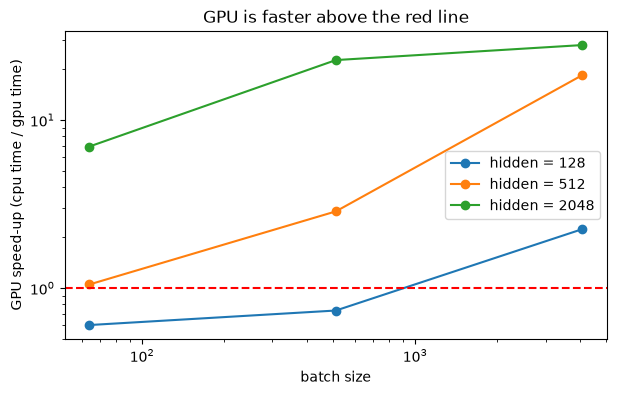

section time: 14 s


In [19]:
# (3) Does the GPU win when the network or the batch gets bigger?  ms per update (forward + backward + Adam)
def nn_update_ms(device, batch, hidden, budget=0.4):
    d = torch.device(device); q = NNQNetwork(n_hidden=hidden).to(d); qt = copy.deepcopy(q); opt = torch.optim.Adam(q.parameters(), lr=5e-4)
    s, s2 = torch.randn(batch, 4, device=d), torch.randn(batch, 4, device=d)
    a, r, dn = torch.randint(0, 2, (batch,), device=d), torch.ones(batch, device=d), torch.zeros(batch, device=d)
    def step():
        q_sa = q(s).gather(1, a.unsqueeze(1)).squeeze(1)
        with torch.no_grad(): y = r + 0.99 * (1 - dn) * qt(s2).max(1).values
        loss = F.smooth_l1_loss(q_sa, y); opt.zero_grad(); loss.backward(); opt.step()
    for _ in range(3): step()
    nn_sync(d); t, n = time.perf_counter(), 0
    while n < 5 or time.perf_counter() - t < budget: step(); n += 1
    nn_sync(d); return (time.perf_counter() - t) / n * 1e3

NN_BATCHES, NN_WIDTHS = (64, 512, 4096), (128, 512, 2048)
t_all = time.perf_counter(); torch.set_num_threads(NN_DEFAULT_THREADS)
nn_grid = {dv: {(b, w): nn_update_ms(dv, b, w) for w in NN_WIDTHS for b in NN_BATCHES} for dv in (["cpu", "cuda"] if HAS_GPU else ["cpu"])}
torch.set_num_threads(1)
print(f"{'hidden':>7s} {'batch':>6s} {'cpu ms':>9s}" + (f" {'gpu ms':>9s} {'speed-up':>9s}" if HAS_GPU else ""))
for w in NN_WIDTHS:
    for b in NN_BATCHES:
        print(f"{w:7d} {b:6d} {nn_grid['cpu'][(b, w)]:9.2f}" + (f" {nn_grid['cuda'][(b, w)]:9.2f} {nn_grid['cpu'][(b, w)]/nn_grid['cuda'][(b, w)]:8.1f}x" if HAS_GPU else ""))
if HAS_GPU:
    plt.figure(figsize=(7, 4))
    for w in NN_WIDTHS: plt.plot(NN_BATCHES, [nn_grid["cpu"][(b, w)] / nn_grid["cuda"][(b, w)] for b in NN_BATCHES], "-o", label=f"hidden = {w}")
    plt.axhline(1, color="r", ls="--"); plt.xscale("log"); plt.yscale("log")
    plt.xlabel("batch size"); plt.ylabel("GPU speed-up (cpu time / gpu time)"); plt.title("GPU is faster above the red line"); plt.legend(); plt.show()
print(f"section time: {time.perf_counter()-t_all:.0f} s")

NVIDIA GeForce RTX 4050 Laptop GPU (6 GB), torch 2.11 with CUDA 12.8, 8 logical CPU cores (torch uses 4 threads by default). Training runs of 5,000 steps, one run per setting.

**The GPU is slower for this network.** The same training took 12.9 s on one CPU thread (386 steps/s), 12.2 s on 4 threads and 23.9 s on the GPU (209 steps/s), so the GPU was 1.8× slower. In an earlier run of the same cell it was 2.3× slower, so the exact ratio changes with the machine's load, but the direction does not. Extra CPU threads buy nothing, which is why the notebook sets `torch.set_num_threads(1)`.

**Why.** Every part of one training step is slower on the GPU: choosing the action (65 µs on the CPU, 584 µs on the GPU), sampling and copying the mini-batch (21 vs 287 µs) and the update itself (1,242 vs 3,777 µs). The environment runs on the CPU, so each step pays a CPU ↔ GPU round trip for the action and a copy of the batch, and a network with 17,410 parameters does too little arithmetic to pay for that.

**When the GPU wins.** Update time grows on the CPU and stays at about 3–4 ms on the GPU, so a bigger network or batch changes the result. Speed-up of the GPU for one update (below 1 the CPU is faster):

| hidden units | batch 64 | batch 512 | batch 4096 |
|---|---|---|---|
| 128 | 0.6× | 0.7× | 2.2× |
| 512 | 1.0× | 2.9× | 18.5× |
| 2048 | 7.0× | 22.7× | 27.9× |

For this project (128 hidden units, batch 64) the answer is to use the CPU. What patience does to the time is read from the steps in the experiment above (24,200 instead of 30,000) and from the Comparisons.

---
# 3. Cores: training on several CPU cores (Bryan)
---
Bryan's notebook is the DQN lab: replay buffer, Q-network, target network and training loop, followed by the experiments A–E of its Part 5. His experiment is `run_configs`, which spreads every (configuration, seed) training over the CPU cores with `joblib.Parallel(n_jobs=8)` instead of running them one after the other. His comment says the results are the same as the sequential version because `train()` sets its own seed, and suggests `n_jobs=6` to keep using the laptop meanwhile. He also added `.long()` in the Part 3 check, because on Windows NumPy returns int32 and `gather()` needs int64.

Below are his cells, run with his settings (50,000 steps, 3 seeds, `n_jobs=8`), and then a short measurement of how the speed changes with the number of cores.

# Lab — DQN with Experience Replay and Target Network

**Intelligent Agents · UC2 · §2.2**

In this lab you build a Deep Q-Network (DQN) in PyTorch that solves **CartPole-v1**. Then you run experiments that show what experience replay and the target network each contribute. The code follows the algorithm from the reading (Hu, 2023), step by step.

**By the end you should be able to:**

- Implement a uniform ring-buffer replay memory with `add()` and `sample()`.
- Build a Q-network as a multilayer perceptron, plus a frozen target copy θ⁻.
- Compute TD targets that handle terminal states correctly, and train with mini-batch SGD.
- Explain, using your own plots, why replay and the target network make learning stable.

**Prerequisites:** Python, NumPy basics, PyTorch tensors and autograd (see the MLP tutorial), and the tabular Q-learning update.

**Format:** pairs, two 2-hour sessions — Parts 1–3 in session 1, Parts 4–5 in session 2.

**How to work in this notebook**

- Complete every cell marked `# TODO`. Replace each `raise NotImplementedError` with your code.
- Run the **self-check** cell after each part. Do not move on until it prints *all checks passed*.
- Do not edit the self-check cells.
- Write your answers to the questions in the **Your answer** cells.

## Setup

You need Python 3.10+, PyTorch and Gymnasium. Everything runs on a laptop CPU; no GPU is needed.

**Environment — CartPole-v1.** A pole is hinged on a cart. The agent pushes the cart left or right to keep the pole upright.

| Element | Value |
| --- | --- |
| State sₜ | 4 floats: cart position, cart velocity, pole angle, pole angular velocity |
| Actions | 2: push left (0), push right (1) |
| Reward | +1 for every step the pole stays up |
| Episode end | `terminated` (pole beyond ±12° or cart beyond ±2.4) or `truncated` (500-step limit) |
| Best possible return | 500 |

In [20]:
# !pip install torch gymnasium numpy matplotlib   # uncomment if the packages are missing
import os

os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')

import copy, random, time
import numpy as np
import torch
import torch.nn as nn
import gymnasium as gym
import matplotlib.pyplot as plt

print("torch", torch.__version__, "| gymnasium", gym.__version__)

torch 2.11.0+cu128 | gymnasium 1.3.0


In [21]:
# Take a look at the environment before you start
env = gym.make("CartPole-v1")
s, _ = env.reset(seed=0)
print("first state:", s)
print("observation space:", env.observation_space)
print("action space:", env.action_space)
env.close()

first state: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space: Discrete(2)


## Part 1 — Replay buffer

Implement uniform random experience replay as described in the slides:

- The buffer has **N** preallocated slots and a counter **c** of all transitions ever added.
- `add`: write at index $i = c \bmod N$ (this overwrites the oldest transition once the buffer is full), then increase $c$.
- `sample(n)`: only when $c \ge n$. Draw $n$ indices uniformly from $[0, \min(c, N))$.

Store each field in its own NumPy array (states, actions, rewards, next states, done flags). Then one mini-batch is a single fancy-indexing call such as `self.s[idx]`.

In [22]:
class ReplayBuffer:
    def __init__(self, capacity, state_dim):
        self.N = capacity
        self.c = 0                                   # transitions ever added
        self.s    = np.zeros((capacity, state_dim), dtype=np.float32)
        self.a    = np.zeros(capacity, dtype=np.int64)
        self.r    = np.zeros(capacity, dtype=np.float32)
        self.s2   = np.zeros((capacity, state_dim), dtype=np.float32)
        self.done = np.zeros(capacity, dtype=np.float32)

    def add(self, s, a, r, s2, done):
        # TODO 1.1  compute i = c mod N
        i = self.c % self.N
        # TODO 1.2  write the five fields at index i (this overwrites the oldest)
        self.s[i]    = s
        self.a[i]    = a
        self.r[i]    = r
        self.s2[i]   = s2
        self.done[i] = done
        # TODO 1.3  increase c
        self.c += 1

    def __len__(self):
        # TODO 1.4  number of valid transitions = min(c, N)
        return min(self.c, self.N)

    def sample(self, n):
        # TODO 1.5  return None while c < n
        if self.c < n:
            return None
        # TODO 1.6  draw n random indices in [0, min(c, N)) and
        #           return (s, a, r, s2, done) as NumPy arrays
        idx = np.random.randint(0, len(self), size=n)
        return self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.done[idx]

**Self-check — Part 1.** This replays the slide example (N = 8, transitions d0 … d11).

In [23]:
buf = ReplayBuffer(capacity=8, state_dim=4)
assert buf.sample(4) is None, "must refuse to sample before c >= n"
for k in range(11):                                  # add d0 ... d10
    buf.add(np.full(4, k), k % 2, float(k), np.full(4, k + 1), 0.0)
assert len(buf) == 8 and buf.c == 11
assert buf.r[3] == 3.0                               # slot 3 still holds d3
buf.add(np.full(4, 11), 1, 11.0, np.full(4, 12), 1.0)  # d11
assert buf.r[3] == 11.0, "d11 must overwrite slot 11 mod 8 = 3"
batches = [buf.sample(8) for _ in range(200)]
r  = np.concatenate([b[2] for b in batches])
s  = np.concatenate([b[0] for b in batches])
s2 = np.concatenate([b[3] for b in batches])
assert set(r.tolist()) == set(range(4, 12)), "samples must cover the whole buffer"
assert np.all(s2[:, 0] == s[:, 0] + 1), "fields of one transition must stay aligned"
print("ReplayBuffer: all checks passed")

ReplayBuffer: all checks passed


### Questions — Part 1

**Q1.1** Why does `sample` draw from `[0, min(c, N))` and not from `[0, N)`?

**Your answer:**

Mientras el buffer no está lleno ($c < N$), solo los primeros $c$ slots contienen transiciones reales; los slots $c, \dots, N-1$ siguen con los ceros de la inicialización. Si muestreáramos de $[0, N)$, entrarían en el mini-batch transiciones falsas (estado 0, acción 0, recompensa 0, no terminal) y la red aprendería objetivos sin sentido. Con $[0, \min(c, N))$ solo se usan datos válidos; una vez lleno el buffer, $\min(c, N) = N$ y se muestrea de todo.

**Q1.2** A Python list of tuples with `pop(0)` would also work. Why is the ring buffer preferred when N = 50,000?

**Your answer:**

`list.pop(0)` cuesta $O(N)$: Python tiene que desplazar los 49,999 elementos restantes en cada paso, y eso se repite en cada uno de los 50,000 pasos. El ring buffer escribe en una posición fija con $i = c \bmod N$, en $O(1)$, sin mover nada y sin reservar memoria nueva. Además, al guardar cada campo en su propio array de NumPy, un mini-batch se obtiene con una sola indexación vectorizada (`self.s[idx]`), ya en el formato que PyTorch necesita; con una lista de tuplas habría que recorrer el batch en Python y reconstruir los arrays en cada actualización.

**Q1.3** The buffer stores `done`, but the slides' tuple is (s, a, r, s′). Where in the algorithm is `done` needed?

**Your answer:**

En el cálculo del objetivo TD (Parte 3): si $s_{j+1}$ es terminal, el objetivo es solo $r_j$; si no, es $r_j + \gamma \max_{a'} \hat Q(s_{j+1}, a'; \theta^-)$. Con la tupla (s, a, r, s′) no se sabe si s′ es terminal, porque un estado terminal parece un estado normal más. Por eso guardamos `done` y lo usamos como máscara: $\delta = r + \gamma (1 - \text{done}) \max_{a'} \hat Q(s', a'; \theta^-)$. Solo se guarda `terminated` (no `truncated`), porque al cortar por el límite de 500 pasos el estado siguiente sí tiene valor futuro.

## Part 2 — Q-network

The Q-network is a small MLP. It takes a state and returns **one Q-value per action**, so a single forward pass scores every action.

Architecture: 4 inputs → 128 → 128 → 2 outputs, with ReLU between layers and **no activation on the output** (Q-values can be any real number).

You also write `select_action`, the ε-greedy policy: with probability ε pick a random action, otherwise pick $\arg\max_a \hat Q(s, a; \theta)$.

In [24]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=128):
        super().__init__()
        # TODO 2.1  nn.Sequential: Linear(state_dim, hidden) → ReLU →
        #           Linear(hidden, hidden) → ReLU → Linear(hidden, n_actions)
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, x):
        return self.net(x)          # shape: (batch, n_actions)


def select_action(q_net, s, eps, n_actions):
    # TODO 2.2  with probability eps return a random action,
    #           otherwise return argmax_a Q(s, a; θ) as a Python int.
    #           Use torch.no_grad(). Hint: the network expects a batch,
    #           so convert s to a tensor of shape (1, state_dim).
    if random.random() < eps:
        return random.randrange(n_actions)
    with torch.no_grad():
        q = q_net(torch.as_tensor(s, dtype=torch.float32).unsqueeze(0))
    return int(q.argmax(dim=1).item())

**Self-check — Part 2**

In [25]:
q = QNetwork(4, 2)
out = q(torch.zeros(32, 4))
assert out.shape == (32, 2)
assert sum(p.numel() for p in q.parameters()) == 4*128+128 + 128*128+128 + 128*2+2
assert select_action(q, np.zeros(4, dtype=np.float32), 0.0, 2) in (0, 1)
print("QNetwork: all checks passed")

QNetwork: all checks passed


### Questions — Part 2

**Q2.1** Why does the network output Q(s, ·) for all actions, instead of taking (s, a) as input and returning one number?

**Your answer:**

Por eficiencia: tanto la selección de acción ($\arg\max_a$) como el objetivo TD ($\max_{a'}$) necesitan el Q-valor de *todas* las acciones. Con salida $Q(s, \cdot)$ basta una sola pasada hacia adelante para obtenerlos todos; con entrada (s, a) harían falta tantas pasadas como acciones. Además, las acciones comparten la representación del estado aprendida en las capas ocultas, y solo difieren en la última capa.

**Q2.2** Why must the last layer have no ReLU?

**Your answer:**

ReLU recorta todo valor negativo a 0, así que la red nunca podría predecir Q-valores negativos, aunque en general pueden serlo (por ejemplo, con recompensas negativas). Además, si una salida cae en la zona negativa, su gradiente es 0 y esa salida deja de aprender ("neurona muerta"). Predecir Q-valores es una regresión sobre números reales, por lo que la salida debe ser lineal. En CartPole los Q-valores son positivos (hasta ≈ 100 con γ = 0.99), pero el segundo problema existe igual.

## Part 3 — Target network and loss

The target network θ⁻ is a deep copy of θ that receives **no gradients**. The loss pulls $\hat Q(s_j, a_j; \theta)$ toward targets computed with θ⁻:

$$
\delta_j = \begin{cases} r_j & \text{if } s_{j+1} \text{ is terminal} \\ r_j + \gamma \max_{a'} \hat{Q}(s_{j+1}, a'; \theta^-) & \text{otherwise} \end{cases}
\qquad
l = \frac{1}{b}\sum_j \big(\delta_j - \hat{Q}(s_j, a_j; \theta)\big)^2
$$

Both cases fit in one line with a mask: $\delta = r + \gamma \cdot (1 - \text{done}) \cdot \max_{a'} \hat Q(s', a'; \theta^-)$.

(The slides use a sum; we use the mean, which only rescales the learning rate.)

> **Terminated ≠ truncated.** Gymnasium returns two flags. Store `done = terminated` only. When the 500-step time limit truncates an episode, the pole has *not* fallen, so the next state still has value and the target must bootstrap. Treating truncation as terminal is a classic bug: it teaches the agent that states near the time limit are worth nothing.

In [26]:
def compute_loss(q_net, target_net, batch, gamma):
    s, a, r, s2, done = (torch.as_tensor(x) for x in batch)
    # TODO 3.1  Q(s_j, a_j; θ): run q_net(s) and pick the taken action
    #           with .gather(1, a.unsqueeze(1)).squeeze(1)
    #           (.long(): gather needs int64 indices; on Windows NumPy may give int32)
    q_sa = q_net(s).gather(1, a.long().unsqueeze(1)).squeeze(1)
    # TODO 3.2  inside torch.no_grad(): max_a' Q(s_{j+1}, a'; θ⁻) from target_net(s2)
    with torch.no_grad():
        max_next = target_net(s2).max(dim=1).values
    # TODO 3.3  delta = r + gamma * (1 - done) * max_next
    delta = r + gamma * (1 - done) * max_next
    # TODO 3.4  return the mean squared error between q_sa and delta
    return ((delta - q_sa) ** 2).mean()

**Self-check — Part 3**

In [27]:
torch.manual_seed(0)
q = QNetwork(4, 2)
qt = copy.deepcopy(q)
b = 16
batch = (np.random.randn(b, 4).astype(np.float32), np.random.randint(0, 2, b),
         np.ones(b, np.float32), np.random.randn(b, 4).astype(np.float32),
         np.ones(b, np.float32))                       # all terminal
loss = compute_loss(q, qt, batch, gamma=0.99)
# .long() agregado: en Windows np.random.randint devuelve int32 y gather() exige int64
q_sa = q(torch.as_tensor(batch[0])).gather(1, torch.as_tensor(batch[1]).long().unsqueeze(1)).squeeze(1)
assert torch.isclose(loss, ((q_sa - 1.0) ** 2).mean()), "terminal target must be r"
loss.backward()
assert all(p.grad is None for p in qt.parameters()), "no gradient may reach θ⁻"
print("compute_loss: all checks passed")

compute_loss: all checks passed


### Questions — Part 3

**Q3.1** What would go wrong if you forgot `torch.no_grad()` in TODO 3.2 and the optimiser held both networks' parameters?

**Your answer:**

Sin `no_grad`, el gradiente de la pérdida también fluiría a través del objetivo $\delta$ hacia los parámetros de θ⁻, y como el optimizador también los tiene, `opt.step()` los modificaría en cada paso. La red objetivo dejaría de estar congelada: se movería en cada actualización, igual que θ, y volvería el problema del *moving target* que justamente se quería evitar. Además, el gradiente empujaría el objetivo hacia la predicción (y no solo la predicción hacia el objetivo), lo que no es la regla de Q-learning y desestabiliza el aprendizaje.

**Q3.2** Why is `copy.deepcopy` needed? What happens with `target_net = q_net`?

**Your answer:**

`target_net = q_net` no crea una copia: solo da un segundo nombre al *mismo* objeto, así que ambos comparten los mismos pesos. Cada `opt.step()` cambiaría también "la red objetivo", y el DQN se comportaría como sin target network (como la corrida B). `copy.deepcopy` crea un objeto nuevo con copias independientes de todos los tensores, de modo que θ⁻ queda congelado hasta la siguiente sincronización `load_state_dict` cada C pasos.

## Part 4 — Training loop

The loop is the DQN algorithm from the slides, line by line. The comments give the pseudocode line numbers from the reading, so you can check each step.

**Starting hyperparameters** — sensible defaults for CartPole, not tuned for this lab. Adjust them if learning is unstable.

| Symbol | Argument | Value |
| --- | --- | --- |
| K | `steps` | 50,000 |
| N | `capacity` | 50,000 |
| b | `batch` | 64 |
| m | `warmup` | 1,000 |
| C | `C` | 500 |
| γ | `gamma` | 0.99 |
| α | `lr` (Adam) | 0.001 |
| ε | `eps_end`, `eps_decay` | 1.0 → 0.05 over 10,000 steps |

`train` returns a log: a list of `(step, episode_return)` pairs, one per finished episode.

In [28]:
def epsilon_by_step(i, eps_start, eps_end, eps_decay):
    # TODO 4.1  linear decay: eps_start at i = 0, eps_end from i = eps_decay onwards
    frac = min(i / eps_decay, 1.0)
    return eps_start + frac * (eps_end - eps_start)


def train(steps=50_000, capacity=50_000, batch=64, warmup=1_000, C=500,
          gamma=0.99, lr=1e-3, eps_end=0.05, eps_decay=10_000,
          use_target=True, seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    env.action_space.seed(seed)
    state_dim, n_actions = env.observation_space.shape[0], env.action_space.n
    q_net = QNetwork(state_dim, n_actions)
    target_net = copy.deepcopy(q_net)                      # θ⁻ ← θ
    opt = torch.optim.Adam(q_net.parameters(), lr=lr)
    buf = ReplayBuffer(capacity, state_dim)

    s, _ = env.reset(seed=seed)                            # line 1
    ep_ret, log = 0.0, []                                  # log: (step, return)
    for i in range(1, steps + 1):                          # line 2
        # TODO 4.2  eps = epsilon_by_step(i, 1.0, eps_end, eps_decay)       (line 6)
        eps = epsilon_by_step(i, 1.0, eps_end, eps_decay)
        # TODO 4.3  a = select_action(...); step the env:                     (lines 3–5)
        #           s2, r, terminated, truncated, _ = env.step(a)
        a = select_action(q_net, s, eps, n_actions)
        s2, r, terminated, truncated, _ = env.step(a)
        # TODO 4.4  buf.add(s, a, r, s2, float(terminated)); s ← s2;         (lines 7–8)
        #           add r to ep_ret
        buf.add(s, a, r, s2, float(terminated))
        s = s2
        ep_ret += r
        # TODO 4.5  if terminated or truncated: append (i, ep_ret) to log,
        #           reset ep_ret to 0 and reset the env
        if terminated or truncated:
            log.append((i, ep_ret))
            ep_ret = 0.0
            s, _ = env.reset()

        if len(buf) > warmup and len(buf) > batch:         # line 9
            # TODO 4.6  sample a mini-batch; compute_loss with target_net
            #           (or q_net when use_target=False); then
            #           opt.zero_grad(), loss.backward(), opt.step()           (lines 10–15)
            mb = buf.sample(batch)
            loss = compute_loss(q_net, target_net if use_target else q_net, mb, gamma)
            opt.zero_grad()
            loss.backward()
            opt.step()
            # TODO 4.7  every C steps: target_net.load_state_dict(q_net.state_dict())
            if i % C == 0:
                target_net.load_state_dict(q_net.state_dict())
    env.close()
    return log

**Self-check — Part 4**

1. Measure a random-policy baseline first: run with `eps_end=1.0` (the network is never used to act).
2. Train the full DQN. It should clearly beat the baseline within 50,000 steps and, on most seeds, reach episodes near the 500 cap.
3. If returns stay at the baseline, check that `opt.step()` runs, that the prediction is **not** computed with `target_net`, and that `done` is `terminated` only.

In [29]:
assert abs(epsilon_by_step(0, 1.0, 0.05, 10_000) - 1.0) < 1e-9
assert abs(epsilon_by_step(5_000, 1.0, 0.05, 10_000) - 0.525) < 1e-9
assert abs(epsilon_by_step(20_000, 1.0, 0.05, 10_000) - 0.05) < 1e-9

t0 = time.time()
base_log = train(steps=20_000, eps_end=1.0, seed=0)
baseline = np.mean([ret for _, ret in base_log])
print(f"random baseline: mean return {baseline:.1f} over {len(base_log)} episodes ({time.time()-t0:.0f}s)")

random baseline: mean return 22.0 over 908 episodes (22s)


381 episodes in 80s | last 20 episodes: 304.2 | best: 500


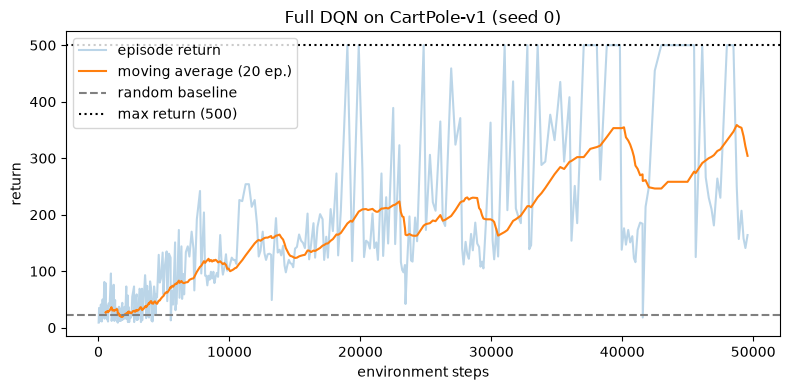

In [30]:
t0 = time.time()
log = train(seed=0)
steps_, rets_ = map(np.array, zip(*log))
print(f"{len(log)} episodes in {time.time()-t0:.0f}s | last 20 episodes: {rets_[-20:].mean():.1f} | best: {rets_.max():.0f}")

plt.figure(figsize=(8, 4))
plt.plot(steps_, rets_, alpha=0.3, label="episode return")
w = 20
plt.plot(steps_[w-1:], np.convolve(rets_, np.ones(w)/w, mode="valid"), label=f"moving average ({w} ep.)")
plt.axhline(baseline, ls="--", c="gray", label="random baseline")
plt.axhline(500, ls=":", c="k", label="max return (500)")
plt.xlabel("environment steps"); plt.ylabel("return"); plt.title("Full DQN on CartPole-v1 (seed 0)")
plt.legend(); plt.tight_layout(); plt.show()

## Part 5 — Experiments

Run each configuration with **3 seeds** (0, 1, 2). Plot the mean episode return ± one standard deviation against environment steps. Change **one thing at a time** from the full DQN of Part 4.

| Run | Change from default | Question it answers |
| --- | --- | --- |
| A — Full DQN | none | Baseline for every comparison |
| B — No target network | `use_target=False` | What does θ⁻ buy in stability? |
| C — Tiny buffer ≈ no replay | `capacity=128`, `warmup=64` | What happens when batches are nearly consecutive? |
| D — Sync period | `C` ∈ {1, 100, 500, 2000} | Where is the stability / staleness trade-off? |
| E — Buffer size | `capacity` ∈ {1,000; 10,000; 50,000} | How much memory is enough? |

The plotting helpers are given. Each configuration trains 3 times, so these cells take a while; lower `STEPS` for a quick first try, then run the full 50,000 steps for your report.

In [31]:
STEPS = 50_000
SEEDS = (0, 1, 2)

def curve(log, grid, window=20):
    steps, rets = map(np.array, zip(*log))
    smooth = np.convolve(rets, np.ones(window) / window, mode="valid")
    return np.interp(grid, steps[window - 1:], smooth)

# run_configs paralelo: reparte cada (configuración, semilla) entre los núcleos de la CPU.
# Da exactamente los mismos resultados que la versión secuencial, porque train() fija su propia semilla.
# Usa n_jobs=6 si quieres seguir usando la laptop mientras corre.
from joblib import Parallel, delayed

def run_configs(runs, steps=STEPS, n_jobs=8):
    grid = np.linspace(5_000, steps, 200)
    jobs = [(label, sd) for label in runs for sd in SEEDS]
    t0 = time.time()
    logs = Parallel(n_jobs=n_jobs)(
        delayed(train)(steps=steps, seed=sd, **runs[label]) for label, sd in jobs)
    results = {}
    for label in runs:
        results[label] = np.stack([curve(log, grid) for (lb, _), log in zip(jobs, logs) if lb == label])
        print(f"{label:>16}: final {results[label][:, -1].mean():6.1f} ± {results[label][:, -1].std():5.1f}")
    print(f"total: {time.time()-t0:.0f}s")
    return grid, results

def plot(grid, results, title, path):
    plt.figure(figsize=(8, 4.5))
    for label, ys in results.items():
        m, sd = ys.mean(0), ys.std(0)
        plt.plot(grid, m, label=label)
        plt.fill_between(grid, m - sd, m + sd, alpha=0.2)
    plt.axhline(baseline, ls="--", c="gray", lw=1, label="random baseline")
    plt.xlabel("environment steps"); plt.ylabel("episode return (moving avg, 20 ep.)")
    plt.title(title); plt.legend(); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

**Runs A–C** — ablation of replay and the target network. Saves `ablation.png`.

      A full DQN: final  271.9 ± 114.4
     B no target: final  288.7 ±  20.1
   C tiny buffer: final  181.4 ±  23.4
total: 260s


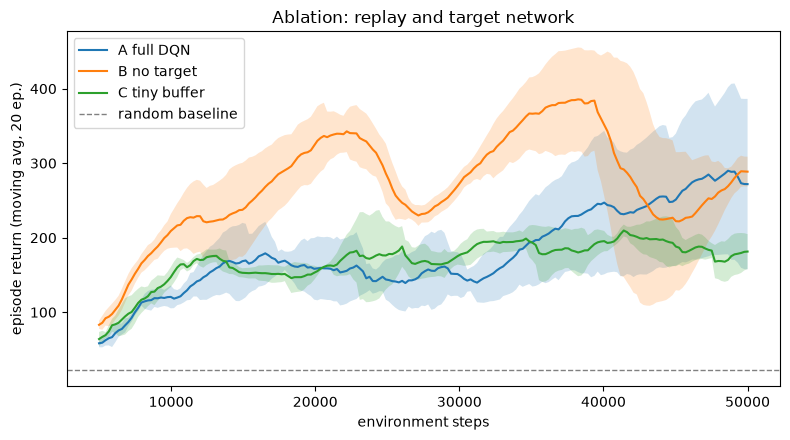

In [32]:
grid, res_abl = run_configs({
    "A full DQN":    {},
    "B no target":   {"use_target": False},
    "C tiny buffer": {"capacity": 128, "warmup": 64},
})
plot(grid, res_abl, "Ablation: replay and target network", "ablation.png")

**Run D** — target sync period C. Saves `sync_period.png`.

           C = 1: final  288.7 ±  20.1
         C = 100: final  481.4 ±   7.0
         C = 500: final  271.9 ± 114.4
        C = 2000: final  117.0 ±  29.0
total: 209s


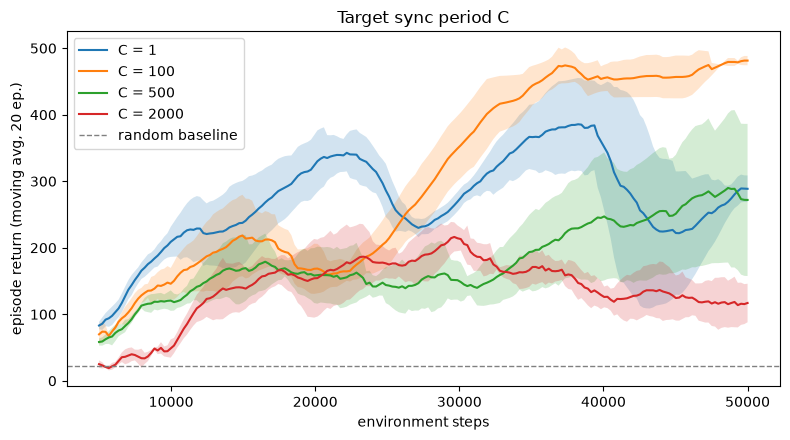

In [33]:
# TODO 5.1  run C ∈ {1, 100, 500, 2000} with run_configs and plot the result
#           as "sync_period.png". Hint: a dict comprehension builds the runs.
grid, res_sync = run_configs({f"C = {c}": {"C": c} for c in (1, 100, 500, 2000)})
plot(grid, res_sync, "Target sync period C", "sync_period.png")

**Run E** — replay capacity N. Saves `buffer_size.png`.

       N = 1,000: final  184.1 ±  19.3
      N = 10,000: final  271.8 ± 100.6
      N = 50,000: final  271.9 ± 114.4
total: 235s


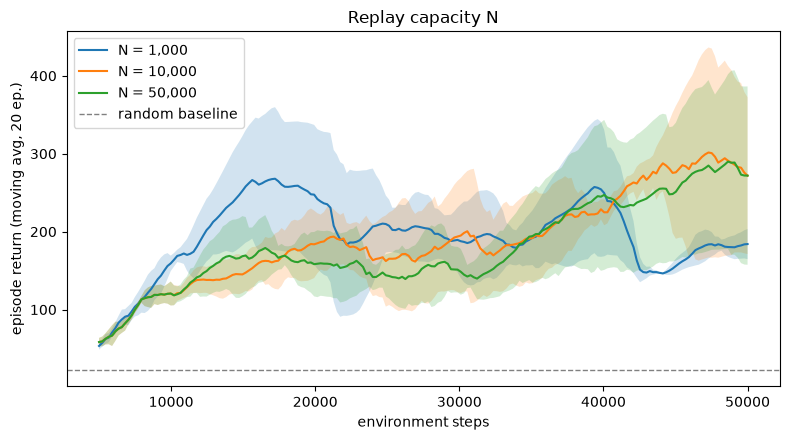

In [34]:
# TODO 5.2  run capacity ∈ {1_000, 10_000, 50_000} and plot the result as "buffer_size.png"
# warmup must stay below capacity, otherwise len(buf) > warmup is never true and
# N = 1,000 never trains; cap it at half the buffer (as in run C: 128 / 64).
grid, res_buf = run_configs({f"N = {n:,}": {"capacity": n, "warmup": min(1_000, n // 2)}
                             for n in (1_000, 10_000, 50_000)})
plot(grid, res_buf, "Replay capacity N", "buffer_size.png")

### Questions — Part 5

**Q5.1** Rank runs A, B and C by final return and by variance across seeds. Link each gap to a problem from the slides (correlation, data efficiency, moving target).

**Your answer:**

_Write your answer here._

**Q5.2** In run D, which C learns fastest and which is most stable? Explain using the staircase picture of θ⁻.

**Your answer:**

_Write your answer here._

**Q5.3** Does `C = 1` behave like run B? Why or why not?

**Your answer:**

_Write your answer here._

**Q5.4** Why can a very large buffer slow learning early on, even though it decorrelates samples better?

**Your answer:**

_Write your answer here._

## Deliverables and grading

Submit one zip per pair with this notebook (all cells run, outputs visible), the figures and a report of at most 4 pages.

- [ ] Parts 1–3 pass their self-checks
- [ ] Full DQN learning curve with the random baseline marked
- [ ] `ablation.png` (runs A–C), `sync_period.png` (run D) and `buffer_size.png` (run E)
- [ ] Every question answered; each figure discussed in 3–5 sentences

| Criterion | Points |
| --- | --- |
| Replay buffer correct (ring indexing, sampling range, alignment) | 15 |
| Q-network and ε-greedy action selection | 10 |
| Loss: target network, `no_grad`, terminal masking, terminated vs truncated | 20 |
| Training loop matches the algorithm (warm-up, sync every C) | 15 |
| Experiments: 3 seeds, mean ± std plots, clear labels | 20 |
| Report: answers link results to correlation, data efficiency and moving targets | 20 |
| **Total** | **100** |

## References

- M. Hu, *The Art of Reinforcement Learning: Fundamentals, Mathematics, and Implementations with Python*, Apress 2023 — [code repository](https://github.com/Apress/art-of-reinforcement-learning)
- I. Gridin, *Practical Deep Reinforcement Learning with Python*, BPB Publications 2022 — [code repository](https://github.com/bpbpublications/Practical-Deep-Reinforcement-Learning-with-Python)
- [Building Multilayer Perceptron Models in PyTorch](https://machinelearningmastery.com/building-multilayer-perceptron-models-in-pytorch/), Machine Learning Mastery
- [Gymnasium CartPole-v1 documentation](https://gymnasium.farama.org/environments/classic_control/cart_pole/)

---
### Speed with more cores
How does the wall-clock time change with 1, 2, 4 and 8 workers for the same work, and are the results really the same? The work is his runs A and B with his 3 seeds, which are 6 trainings of 6,000 steps. The machine has 8 logical cores (4 physical).

n_jobs = 1:   37.5 s wall


n_jobs = 2:   27.7 s wall


n_jobs = 4:   20.9 s wall


n_jobs = 8:   18.1 s wall

n_jobs  seconds  speed-up  efficiency   identical curves to n_jobs=1
     1     37.5     1.00x        100%                           True
     2     27.7     1.35x         68%                           True
     4     20.9     1.79x         45%                           True
     8     18.1     2.07x         26%                           True


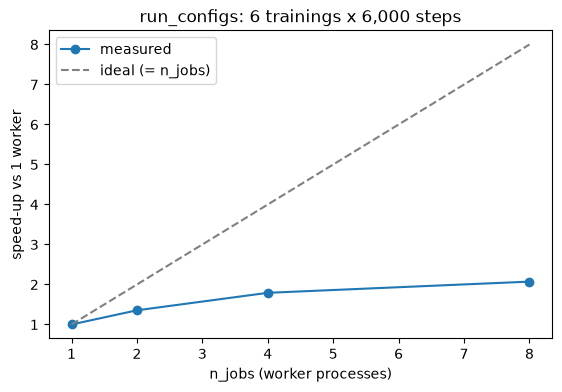

In [35]:
import io, contextlib
SC_RUNS = {"A full DQN": {}, "B no target": {"use_target": False}}
SC_STEPS = 6_000
sc = {}
for n in (1, 2, 4, 8):
    t0 = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()):                    # hide his per-run prints
        g_, res_ = run_configs(SC_RUNS, steps=SC_STEPS, n_jobs=n)      # Bryan's run_configs
    sc[n] = dict(seconds=time.perf_counter() - t0, res=res_)
    print(f"n_jobs = {n}: {sc[n]['seconds']:6.1f} s wall")

t1 = sc[1]["seconds"]
print(f"\n{'n_jobs':>6s} {'seconds':>8s} {'speed-up':>9s} {'efficiency':>11s} {'identical curves to n_jobs=1':>30s}")
for n, r in sc.items():
    same = all(np.array_equal(r["res"][k], sc[1]["res"][k]) for k in SC_RUNS)
    print(f"{n:6d} {r['seconds']:8.1f} {t1/r['seconds']:8.2f}x {100*t1/r['seconds']/n:10.0f}% {str(same):>30s}")

plt.figure(figsize=(6.5, 4)); ns = list(sc)
plt.plot(ns, [t1 / sc[n]["seconds"] for n in ns], "-o", label="measured"); plt.plot(ns, ns, "--", c="gray", label="ideal (= n_jobs)")
plt.xlabel("n_jobs (worker processes)"); plt.ylabel("speed-up vs 1 worker"); plt.title("run_configs: 6 trainings x 6,000 steps"); plt.legend(); plt.show()

**Bryan's Part 5 on 8 cores (his settings: 50,000 steps, 3 seeds, `n_jobs=8`).** The score is the final moving average of the training returns.

- **A, B, C (replay and target network):** full DQN 271.9 ± 114.4, no target network 288.7 ± 20.1, tiny buffer 181.4 ± 23.4. The tiny buffer is clearly the worst. The full DQN and the version without a target network are not separable with 3 seeds, and the full DQN has the largest spread.
- **D (target sync period C):** C = 1 gives 288.7 ± 20.1, the same numbers as no target network, which makes sense because copying at every step removes the delay. C = 100 is the best by far (481.4 ± 7.0), the lab's default C = 500 gives 271.9 ± 114.4, and C = 2000 is the worst (117.0 ± 29.0), where the target is too old. A shorter delay helps here, which is the same idea as our soft target.
- **E (buffer size):** N = 1,000 gives 184.1 ± 19.3, while N = 10,000 and N = 50,000 give the same result (271.8 and 271.9). A bigger buffer stops helping after 10,000.
- **Time:** the 30 trainings of A–E took 260 + 209 + 235 = 704 s (11.7 min) on 8 cores. One 50,000-step training alone took 80 s, so running the 30 one after another would take about 40 minutes (an estimate, 30 × 80 s), roughly 3.4× longer.

**Speed with more cores (6 trainings of 6,000 steps):**

| `n_jobs` | Time | Speed-up | Identical curves |
|---|---|---|---|
| 1 | 37.5 s | 1.00× | (reference) |
| 2 | 27.7 s | 1.35× | True |
| 4 | 20.9 s | 1.79× | True |
| 8 | 18.1 s | 2.07× | True |

- **His claim holds: more cores change the time, not the result.** The training curves are identical at 1, 2, 4 and 8 workers, because each `train()` sets its own seeds.
- **The speed-up is real but well below linear.** With only 6 trainings, 8 workers can use at most 6, the laptop has 4 physical cores, and every worker has to start Python and import `torch` before it trains. In an earlier run of this same cell the 1-worker time was 61.5 s and 8 workers gave 2.88×, so the exact speed-up changes from run to run (between about 2× and 3× at 8 workers) while the identical results do not.
- **Cores pay off for many or long trainings.** His Part 5 (30 long trainings) gets about 3.4×, while 6 short trainings get about 2×, because the start-up cost is fixed.

---
# 4. Comparisons
---
We compare, on the same 5 training seeds (400–404) and the same 50 new test episodes (seeds 40,000–40,049):

- the rule `angle + K·angular velocity` from part 1 (no training),
- the original DQN of the lab (`train()` with its default settings, 30,000 steps),
- our neural network (improved DQN with patience),
- and the two DQNs trained on 8 cores instead of 1.

The score is the mean return of the greedy policy. The time is the wall-clock time of the 5 trainings. The 8-core times are measured. The 1-core times are estimated as 5 × the time of one training run alone, since running all five in a row would take several more minutes.

In [36]:
CMP_SEEDS = (400, 401, 402, 403, 404)
CMP_TEST  = range(40_000, 40_050)

def lab_dqn_run(seed):
    # The lab's train() with its default settings except the 30,000-step budget. Its QNetwork is wrapped during the call
    # to keep the network it builds, because train() only returns the episode log.
    box = {}
    class _Capture(QNetwork):                                     # QNetwork = the lab's class (part 3)
        def __init__(self, *a, **k):
            super().__init__(*a, **k); box["q"] = self
    g = train.__globals__; orig = g["QNetwork"]; g["QNetwork"] = _Capture
    t0 = time.perf_counter()
    try:    log = train(seed=seed, steps=30_000)
    finally: g["QNetwork"] = orig
    return dict(seed=seed, state={k: v.clone() for k, v in box["q"].state_dict().items()}, log=log,
                seconds=time.perf_counter() - t0, steps=30_000)

def nn_cmp_run(seed):
    out = train_nn(seed=seed, steps=30_000, double=True, tau=0.02, patience=NN_PATIENCE, grace=NN_GRACE)
    return dict(seed=seed, state={k: v.clone() for k, v in out["q"].state_dict().items()}, seconds=out["seconds"], steps=out["steps_used"])

def cmp_batch(fn, seeds, n_jobs):
    t0 = time.perf_counter()
    runs = Parallel(n_jobs=n_jobs)(delayed(fn)(s) for s in seeds)
    return time.perf_counter() - t0, runs

cmp = {}
for arm, fn in (("Original DQN", lab_dqn_run), ("NN", nn_cmp_run)):
    wall_par, runs_par = cmp_batch(fn, CMP_SEEDS, 8)               # 5 trainings over 8 cores (quality numbers come from here)
    wall_seq, runs_seq = cmp_batch(fn, CMP_SEEDS[:1], 1)           # 1 training alone on 1 core
    cmp[arm] = dict(wall_par=wall_par, runs=runs_par, wall_seq1=wall_seq, runs_seq=runs_seq, wall_seq5_est=wall_seq * 5)
    print(f"{arm:13s} parallel x5 on 8 cores: {wall_par:6.1f} s | sequential x1 on 1 core: {wall_seq:6.1f} s -> sequential x5 estimated {wall_seq*5:.0f} s", flush=True)
    print(f"              steps per run (parallel batch): {[r['steps'] for r in runs_par]}")

def cmp_score(runs, net):
    out = []
    for r in runs:
        m = net(); m.load_state_dict(r["state"]); out.append(nn_run_policy(m, CMP_TEST))
    return np.array(out)

cmp["Original DQN"]["test"] = cmp_score(cmp["Original DQN"]["runs"], lambda: QNetwork(4, 2))
cmp["NN"]["test"]     = cmp_score(cmp["NN"]["runs"], NNQNetwork)
same = {a: all(torch.equal(s["state"][k], p["state"][k]) for s, p in zip(cmp[a]["runs_seq"], cmp[a]["runs"][:1]) for k in s["state"]) for a in cmp}
print(f"\nsequential (1 core) and parallel (8 cores) give identical trained weights for seed 400: original DQN {same['Original DQN']}, NN {same['NN']}")

Original DQN  parallel x5 on 8 cores:   86.8 s | sequential x1 on 1 core:   57.2 s -> sequential x5 estimated 286 s


              steps per run (parallel batch): [30000, 30000, 30000, 30000, 30000]


NN            parallel x5 on 8 cores:   83.8 s | sequential x1 on 1 core:   47.8 s -> sequential x5 estimated 239 s


              steps per run (parallel batch): [24000, 24000, 25000, 24000, 24000]



sequential (1 core) and parallel (8 cores) give identical trained weights for seed 400: original DQN True, NN True


In [37]:
def cmp_rule(K_, seeds=CMP_TEST):
    env, rets = gym.make("CartPole-v1"), []
    for sd in seeds:
        o, _ = env.reset(seed=int(sd)); tot, done = 0.0, False
        while not done:
            o, r, te, tr, _ = env.step(0 if o[2] + K_ * o[3] < 0 else 1); tot += r; done = te or tr
        rets.append(tot)
    env.close(); return float(np.mean(rets))

t0 = time.perf_counter(); r1, r05 = cmp_rule(1.0), cmp_rule(0.5); rule_secs = time.perf_counter() - t0
lab, nn_ = cmp["Original DQN"], cmp["NN"]
rows = [("Rule angle + K*ang_vel, K=1", [r1], 0, rule_secs, "measured"),
        ("Rule, K=0.5 (tuned on other seeds)", [r05], 0, rule_secs, "measured"),
        ("Original DQN, 1 core (5 trainings)", lab["test"], np.mean([r["steps"] for r in lab["runs"]]), lab["wall_seq5_est"], "estimated: 5 x one run"),
        ("Original DQN, 8 cores", lab["test"], np.mean([r["steps"] for r in lab["runs"]]), lab["wall_par"], "measured"),
        ("NN, 1 core (5 trainings)", nn_["test"], np.mean([r["steps"] for r in nn_["runs"]]), nn_["wall_seq5_est"], "estimated: 5 x one run"),
        ("NN, 8 cores", nn_["test"], np.mean([r["steps"] for r in nn_["runs"]]), nn_["wall_par"], "measured")]

print(f"{'arm':40s} {'test return by seed (400-404)':>32s} {'mean':>6s} {'steps/run':>10s} {'batch wall s':>13s}  {'basis'}")
for name, t, steps, wall, basis in rows:
    t = np.atleast_1d(t)
    print(f"{name:40s} {str([round(x) for x in t]) if len(t) > 1 else '(deterministic)':>32s} {t.mean():6.1f} {steps:10.0f} {wall:13.1f}  {basis}")

print(f"\nmeasured: 1 training alone on 1 core  -> original DQN {lab['wall_seq1']:.0f} s, NN {nn_['wall_seq1']:.0f} s")
print(f"speed-up from 8 cores, original DQN : {lab['wall_seq5_est']/lab['wall_par']:.2f}x  (estimated 1-core {lab['wall_seq5_est']:.0f} s -> measured 8-core {lab['wall_par']:.0f} s)")
print(f"speed-up from 8 cores, NN           : {nn_['wall_seq5_est']/nn_['wall_par']:.2f}x  (estimated 1-core {nn_['wall_seq5_est']:.0f} s -> measured 8-core {nn_['wall_par']:.0f} s)")
print(f"NN vs original DQN, 1 core     : {nn_['wall_seq1']/lab['wall_seq1']:.2f}x the time of the original (one training each: {nn_['wall_seq1']:.0f} s vs {lab['wall_seq1']:.0f} s)")

arm                                         test return by seed (400-404)   mean  steps/run  batch wall s  basis


Rule angle + K*ang_vel, K=1                               (deterministic)  500.0          0           0.3  measured
Rule, K=0.5 (tuned on other seeds)                        (deterministic)  500.0          0           0.3  measured
Original DQN, 1 core (5 trainings)              [141, 161, 130, 112, 148]  138.2      30000         286.0  estimated: 5 x one run
Original DQN, 8 cores                           [141, 161, 130, 112, 148]  138.2      30000          86.8  measured
NN, 1 core (5 trainings)                        [500, 408, 500, 500, 493]  480.3      24200         238.8  estimated: 5 x one run
NN, 8 cores                                     [500, 408, 500, 500, 493]  480.3      24200          83.8  measured

measured: 1 training alone on 1 core  -> original DQN 57 s, NN 48 s
speed-up from 8 cores, original DQN : 3.29x  (estimated 1-core 286 s -> measured 8-core 87 s)
speed-up from 8 cores, NN           : 2.85x  (estimated 1-core 239 s -> measured 8-core 84 s)
NN vs original DQN

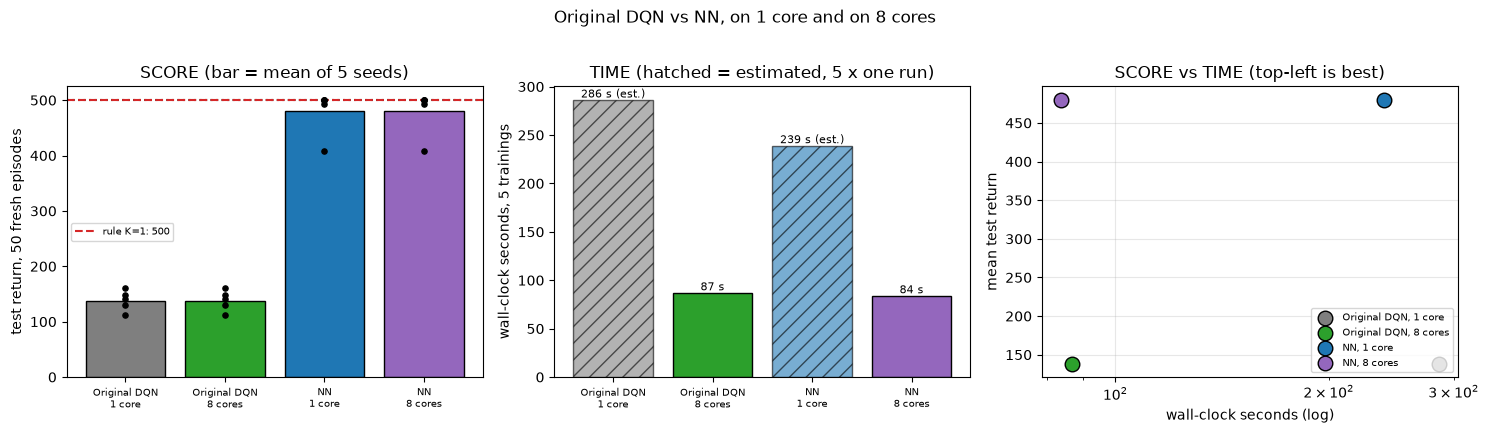

In [38]:
arms = ["Original DQN, 1 core", "Original DQN, 8 cores", "NN, 1 core", "NN, 8 cores"]
quality = {arms[0]: lab["test"], arms[1]: lab["test"], arms[2]: nn_["test"], arms[3]: nn_["test"]}
wall = {arms[0]: lab["wall_seq5_est"], arms[1]: lab["wall_par"], arms[2]: nn_["wall_seq5_est"], arms[3]: nn_["wall_par"]}
est = {arms[0]: True, arms[1]: False, arms[2]: True, arms[3]: False}
colors = {arms[0]: "tab:gray", arms[1]: "tab:green", arms[2]: "tab:blue", arms[3]: "tab:purple"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2)); lab = [a.replace(", ", "\n").replace(": ", ":\n") for a in arms]
for i, a in enumerate(arms):
    t = quality[a]; ax[0].bar(i, t.mean(), color=colors[a], edgecolor="k"); ax[0].scatter([i]*len(t), t, c="k", s=14, zorder=3)
ax[0].axhline(500, ls=":", c="k"); ax[0].axhline(r1, ls="--", c="tab:red", label=f"rule K=1: {r1:.0f}")
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(lab, fontsize=7); ax[0].set_ylabel("test return, 50 fresh episodes"); ax[0].set_title("SCORE (bar = mean of 5 seeds)"); ax[0].legend(fontsize=7)
for i, a in enumerate(arms):
    ax[1].bar(i, wall[a], color=colors[a], edgecolor="k", hatch="//" if est[a] else None, alpha=0.6 if est[a] else 1)
    ax[1].text(i, wall[a], f"{wall[a]:.0f} s" + (" (est.)" if est[a] else ""), ha="center", va="bottom", fontsize=8)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(lab, fontsize=7); ax[1].set_ylabel("wall-clock seconds, 5 trainings"); ax[1].set_title("TIME (hatched = estimated, 5 x one run)")
for a in arms: ax[2].scatter(wall[a], quality[a].mean(), s=110, c=colors[a], edgecolor="k", label=a, zorder=3)
ax[2].set_xscale("log"); ax[2].set_xlabel("wall-clock seconds (log)"); ax[2].set_ylabel("mean test return"); ax[2].set_title("SCORE vs TIME (top-left is best)"); ax[2].legend(fontsize=7, loc="lower right"); ax[2].grid(alpha=0.3)
plt.suptitle("Original DQN vs NN, on 1 core and on 8 cores", y=1.02); plt.tight_layout(); plt.show()

Training seeds 400–404, scored on 50 new episodes (seeds 40,000–40,049). Both DQNs got 30,000 steps.

| | Test return by seed | Mean | Steps per run | Time for 5 trainings |
|---|---|---|---|---|
| Rule `angle + K·ang_vel` (part 1) | deterministic | 500.0 | none | 0.3 s |
| Original DQN, 1 core | 141 / 161 / 130 / 112 / 148 | 138.2 | 30,000 | about 286 s (estimated) |
| Original DQN, 8 cores | the same networks | 138.2 | 30,000 | 86.8 s (measured) |
| NN, 1 core | 500 / 408 / 500 / 500 / 493 | 480.3 | 24,200 | about 239 s (estimated) |
| NN, 8 cores | the same networks | 480.3 | 24,200 | 83.8 s (measured) |

- **Score: the NN is far better than the original DQN** (480.3 against 138.2) on the same seeds and the same test episodes. Part of the gap is the recipe and part is returning the best weights, which the lab's `train()` does not do. The experiment in part 2 separates the two: plain DQN goes from 148 to 367 just by returning the best checkpoint, and the improved recipe adds about 114 more.
- **Neither DQN beats the rule.** `angle + K·angular velocity` scores 500 on these episodes (with K = 1 and with K = 0.5) in 0.3 s and without any training. The NN needs about 24,000 steps of play to get close.
- **More cores change the time, not the score.** The networks trained on 8 cores are identical to those trained on 1 (checked for seed 400 in both arms), and the batch of 5 trainings is about 3.3× faster for the original DQN (87 s instead of about 286 s) and 2.9× faster for the NN (84 s instead of about 239 s).
- **Time of one training on 1 core:** 57 s for the original DQN and 48 s for the NN. In another run of the same cell it was 45 s and 50 s, so the two cost about the same. The NN does more work per step (double DQN, validation every 1,000 steps) but uses 19% fewer steps.
- **Both ideas together** (NN on 8 cores) give the best score in the shortest time that a neural network took: 480.3 in 84 s for 5 trainings.
- **Limits:** 5 seeds. The 1-core times are estimates (5 × one training), while the 8-core times are measured with 5 workers on 4 physical cores. The original DQN was trained for 30,000 steps, not the lab's default of 50,000, so that its budget matches the NN's.

## Ideas to improve the CartPole activity

**The class activity**
1. **Make the human-play answer match its output.** The stored run quit at once (`Score: 0.0`) while the text describes a score of 8 and a falling pole.
2. **Finish `policy_mine` and tune K.** With K = 1 some episodes end with the cart leaving the track. In checks outside this notebook, K = 0.25 and 0.5 scored 500 on 200 unseen seeds, and adding cart terms (`+ 0.1·x + 0.1·x_dot`) also gave 500.
3. **Make Experiment A measure something.** Pass the reset options into `evaluate_policy` and average over episodes. Outside this notebook, widening the start noise from ±0.05 to ±0.3 cut the score from 491.7 to 163.1, and about 31% of those starts begin outside the 12° limit, so part of the drop cannot be won.
4. **Make Experiment C a real ablation.** `policy_no_vel` is `policy_angle` again. Compare both variables, angle only and angular velocity only.
5. **Count how episodes end, not only the return.** Angle only fails by the pole falling, angular velocity only by the cart leaving the track. A std of 36 can come from one episode of 334 among perfect ones.

**The neural network**
6. **Always keep the best checkpoint, and give patience a grace period.** Both mattered in the experiment above.
7. **Validate on episode return and report on new episodes.** The loss keeps changing while the return swings between 100 and 500, and a score measured on the episodes used for tuning is too optimistic.
8. **Test the neighbours of a tuned setting.** τ = 0.02 worked and τ = 0.05 collapsed.
9. **Use the CPU for small networks** and show the batch-size sweep so students see when the GPU starts to pay off.

**The cores**
10. **Change the lab's default target sync.** In Bryan's runs, C = 100 scored 481.4 against 271.9 for the default C = 500.
11. **Size `n_jobs` to the physical cores.** The speed-up is real but below linear, and short runs lose time starting the worker processes. Keep the seeding inside `train()`, because that is what makes parallel and sequential runs identical.